# Paso 2: Nivel Micro — Clasificación de Edificaciones en el Distrito de Puno

**Curso:** Estructuras de Datos Avanzadas (EDA) — Unidad 2  
**Objetivo:** Construir un pipeline completo de ingeniería de variables espaciales (usando `KD-Tree`), fundamentar matemáticamente y **visualizar completamente (sin recortar hojas)** los **4 modelos obligatorios basados en árboles** sobre las edificaciones de Puno:
1. `DecisionTreeClassifier` (comparando **Gini** vs. **Entropía**)
2. `RandomForestClassifier` (*Bagging* en paralelo)
3. `XGBClassifier` (*XGBoost* — *Gradient Boosting* por niveles)
4. `LGBMClassifier` (*LightGBM* — *Leaf-wise Boosting* basado en histogramas)

### ¿Qué problema real estamos resolviendo?
En OpenStreetMap (OSM), de las **652 edificaciones** mapeadas en el Distrito de Puno, más del 70% **no tiene etiquetada su función urbana**.  
En este cuaderno:
1. Construimos un conjunto verificable de **184 edificaciones etiquetadas** en **3 clases urbanas**: `Residencial`, `Comercial_Servicios` e `Institucional`.
2. Extraemos **11 variables predictoras ($X$)** morfológicas y espaciales usando proyección métrica (`EPSG:32719`) y **`cKDTree`**.
3. Explicamos paso a paso la **validación (`80% Train / 20% Test` + `5-Fold CV`)**, el **respaldo matemático**, los **árboles completos de los 4 modelos** y la **lectura de la matriz de confusión**.
4. Reentrenamos el modelo ganador con el **100% de las 184 verificadas** para predecir e imputar el uso de las **468 edificaciones sin etiqueta**.

## 1. Importación de Librerías y Carga de Capas de Puno

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from scipy.spatial import cKDTree

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import folium
from folium.plugins import Fullscreen, MiniMap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 300,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold'
})

# Rutas del proyecto
DIR_DATA_PUNO = Path("../data_puno")
DIR_FIGURES = Path("../figures")
DIR_FIGURES.mkdir(parents=True, exist_ok=True)

# Cargar capas livianas generadas en el Paso 1
gdf_boundary = gpd.read_file(DIR_DATA_PUNO / "puno_distrito_boundary.geojson")
gdf_buildings = gpd.read_file(DIR_DATA_PUNO / "puno_buildings.geojson")
gdf_roads = gpd.read_file(DIR_DATA_PUNO / "puno_roads.geojson")
gdf_pois = gpd.read_file(DIR_DATA_PUNO / "puno_pois.geojson")

print(f"Edificaciones cargadas: {len(gdf_buildings)}")
print(f"Tramos de vías cargados: {len(gdf_roads)}")
print(f"POIs cargados: {len(gdf_pois)}")
print(f"CRS original: {gdf_buildings.crs}")

Edificaciones cargadas: 652
Tramos de vías cargados: 4276
POIs cargados: 935
CRS original: EPSG:4326


### Proyección a Coordenadas Métricas (`EPSG:32719` — UTM Zona 19 Sur)

Las capas originales están en `EPSG:4326` (latitud y longitud en grados). Para calcular áreas en $\text{m}^2$ y distancias exactas en metros en Puno, proyectamos a **WGS 84 / UTM Zone 19S (`EPSG:32719`)**.

In [2]:
CRS_METRICO = "EPSG:32719"

b_utm = gdf_buildings.to_crs(CRS_METRICO).copy()
roads_utm = gdf_roads.to_crs(CRS_METRICO).copy()
pois_utm = gdf_pois.to_crs(CRS_METRICO).copy()

# Punto de referencia: Plaza de Armas de Puno (proyectado a UTM)
plaza_armas_utm = gpd.GeoSeries([Point(-70.0280, -15.8402)], crs="EPSG:4326").to_crs(CRS_METRICO).iloc[0]

print("Capas proyectadas correctamente a UTM Zona 19S (metros).")

Capas proyectadas correctamente a UTM Zona 19S (metros).


## 2. Construcción de la Variable Objetivo ($y$): Etiquetado Verificable

Al inspeccionar `puno_buildings.geojson` vimos que solo **127** edificaciones traen el atributo `type`, pero otras decenas cuentan con su **nombre oficial** (`name`) o un **POI registrado exactamente dentro** (`hotel`, `restaurant`, `school`, `bank`, etc.).

Consolidamos estas señales verificables en **3 clases urbanas claras y balanceadas**:
1. **`Residencial`**: Viviendas (`house`).
2. **`Comercial_Servicios`**: Hoteles, restaurantes, mercados, bancos, comercio minorista, almacenes, terminal.
3. **`Institucional`**: Colegios, universidades/facultades, hospitales, clínicas, iglesias, comisarías, municipalidad, gobierno regional, bomberos, estadios.

Las edificaciones sin etiqueta o ambiguas (`roof`, `construction`, etc.) quedan como `NaN` para ser **clasificadas al final por nuestro modelo ganador**.

In [3]:
# Cruce espacial: identificar si existe un POI exactamente dentro de la edificación
join_poi = gpd.sjoin(b_utm[['osm_id', 'geometry']], pois_utm[['fclass', 'geometry']], how='left', predicate='intersects')
poi_por_edificio = join_poi.dropna(subset=['fclass']).groupby('osm_id')['fclass'].first()
b_utm['poi_interno'] = b_utm['osm_id'].map(poi_por_edificio)

# Reglas de mapeo limpias y transparentes
MAPA_TYPE = {
    'house': 'Residencial',
    'hotel': 'Comercial_Servicios', 'retail': 'Comercial_Servicios',
    'industrial': 'Comercial_Servicios', 'warehouse': 'Comercial_Servicios',
    'train_station': 'Comercial_Servicios', 'greenhouse': 'Comercial_Servicios',
    'school': 'Institucional', 'university': 'Institucional',
    'church': 'Institucional', 'chapel': 'Institucional',
    'stadium': 'Institucional', 'civic': 'Institucional'
}

MAPA_POI = {
    'hotel': 'Comercial_Servicios', 'restaurant': 'Comercial_Servicios',
    'hostel': 'Comercial_Servicios', 'cafe': 'Comercial_Servicios',
    'atm': 'Comercial_Servicios', 'bank': 'Comercial_Servicios',
    'guesthouse': 'Comercial_Servicios', 'bar': 'Comercial_Servicios',
    'laundry': 'Comercial_Servicios', 'convenience': 'Comercial_Servicios',
    'tourist_info': 'Comercial_Servicios', 'marketplace': 'Comercial_Servicios',
    'clothes': 'Comercial_Servicios', 'bakery': 'Comercial_Servicios',
    'consulate': 'Institucional', 'dentist': 'Institucional',
    'museum': 'Institucional', 'college': 'Institucional',
    'hospital': 'Institucional', 'library': 'Institucional',
    'doctors': 'Institucional', 'clinic': 'Institucional',
    'school': 'Institucional', 'artwork': 'Institucional'
}

KEYWORDS_COMERCIAL = [
    'mercado', 'internet', 'bitel', 'frutería', 'hostel', 'hotel',
    'terminal', 'hacienda', 'tienda', 'banco', 'condor'
]
KEYWORDS_INSTITUCIONAL = [
    'iglesia', 'bomberos', 'agencia agraria', 'comisaría', 'care', 'ong',
    'inei', 'facultad', 'centro de salud', 'quisco', 'hospital', 'colegio',
    'sanidad', 'capilla', 'santuario', 'santuiario', 'autoridad', 'sunarp',
    'crematorio', 'dirección regional', 'seguridad ciudadana', 'catedral',
    'municipalidad', 'gobierno regional'
]

def asignar_clase_edificio(row):
    if pd.notnull(row['name']):
        nombre = str(row['name']).lower()
        if any(k in nombre for k in KEYWORDS_INSTITUCIONAL):
            return 'Institucional'
        if any(k in nombre for k in KEYWORDS_COMERCIAL):
            return 'Comercial_Servicios'
    if pd.notnull(row['type']) and row['type'] in MAPA_TYPE:
        return MAPA_TYPE[row['type']]
    if pd.notnull(row['poi_interno']) and row['poi_interno'] in MAPA_POI:
        return MAPA_POI[row['poi_interno']]
    return np.nan

b_utm['clase_uso'] = b_utm.apply(asignar_clase_edificio, axis=1)

conteo = b_utm['clase_uso'].value_counts(dropna=False)
print("Distribución de etiquetas en las 652 edificaciones:")
print(conteo)
print(f"\nTotal etiquetadas (Verificadas): {b_utm['clase_uso'].notnull().sum()}")
print(f"Total sin etiqueta (A predecir): {b_utm['clase_uso'].isnull().sum()}")

Distribución de etiquetas en las 652 edificaciones:
clase_uso
NaN                    468
Residencial             73
Institucional           60
Comercial_Servicios     51
Name: count, dtype: int64

Total etiquetadas (Verificadas): 184
Total sin etiqueta (A predecir): 468


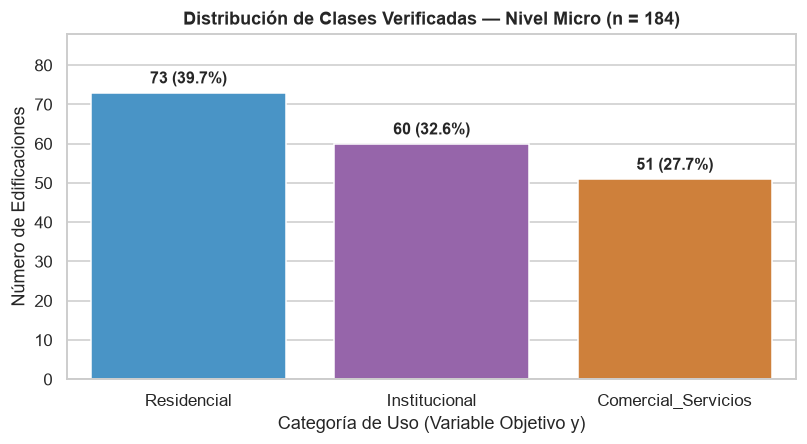

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
orden_clases = ['Residencial', 'Institucional', 'Comercial_Servicios']
colores = ['#3498db', '#9b59b6', '#e67e22']

sns.countplot(data=b_utm.dropna(subset=['clase_uso']), x='clase_uso', order=orden_clases, palette=colores, ax=ax)
ax.set_title("Distribución de Clases Verificadas — Nivel Micro (n = 184)", fontsize=12, fontweight='bold')
ax.set_xlabel("Categoría de Uso (Variable Objetivo y)")
ax.set_ylabel("Número de Edificaciones")
ax.set_ylim(0, 88)
total_lab = b_utm['clase_uso'].notnull().sum()
for p in ax.patches:
    h = int(p.get_height())
    ax.annotate(f"{h} ({h/total_lab*100:.1f}%)", (p.get_x() + p.get_width() / 2., h + 1.5),
                ha='center', va='bottom', fontsize=10.5, fontweight='bold')
plt.tight_layout()
plt.show()

## 3. Ingeniería de Variables ($X$): Morfología + Entorno Espacial con `KD-Tree`

Aquí conectamos las **Estructuras de Datos Avanzadas (`cKDTree`, búsquedas en $O(\log N)$)** con los **Modelos de Árboles**:

### A. Variables Morfológicas (5 variables geométricas)
1. `area_m2`: Área construida en $\text{m}^2$.
2. `perimetro_m`: Perímetro del polígono en metros.
3. `compacidad`: Índice de Polsby-Popper $C = \frac{4\pi \cdot \text{Área}}{\text{Perímetro}^2} \in (0, 1]$.
4. `relacion_aspecto`: Largo / Ancho del rectángulo mínimo rotado.
5. `num_vertices`: Número de vértices del polígono (complejidad arquitectónica).

### B. Variables Espaciales y de Proximidad (6 variables con `cKDTree` y red vial)
6. `dist_plaza_armas_m`: Distancia en metros a la Plaza de Armas de Puno.
7. `dist_via_cercana_m`: Distancia en metros a la vía más cercana.
8. `jerarquia_via`: Jerarquía vial (`3`: Arterial/Secundaria, `2`: Terciaria, `1`: Residencial/Local, `0`: Peatonal/Camino).
9. `densidad_edificios_150m`: Edificios vecinos en un radio de 150 m (`cKDTree`).
10. `dist_vecino_cercano_m`: Distancia al edificio vecino más cercano (`cKDTree`).
11. `pois_entorno_300m`: Servicios/comercios en 300 m (`cKDTree`), excluyendo POIs internos ($\le 1\text{ m}$) para garantizar **cero fuga de datos (*zero data leakage*)**.

In [5]:
# --- A. VARIABLES MORFOLÓGICAS ---
b_utm['area_m2'] = b_utm.geometry.area
b_utm['perimetro_m'] = b_utm.geometry.length
b_utm['compacidad'] = (4 * np.pi * b_utm['area_m2']) / (b_utm['perimetro_m'] ** 2 + 1e-9)

def calcular_aspect_ratio_y_vertices(geom):
    if geom.geom_type == 'Polygon':
        n_vert = len(geom.exterior.coords) - 1
    elif geom.geom_type == 'MultiPolygon':
        n_vert = sum(len(p.exterior.coords) - 1 for p in geom.geoms)
    else:
        n_vert = 0

    rect = geom.minimum_rotated_rectangle
    if rect.geom_type != 'Polygon':
        return 1.0, n_vert
    coords = list(rect.exterior.coords)
    lado1 = Point(coords[0]).distance(Point(coords[1]))
    lado2 = Point(coords[1]).distance(Point(coords[2]))
    largo = max(lado1, lado2)
    ancho = min(lado1, lado2)
    return largo / (ancho + 1e-6), n_vert

resultados_forma = b_utm.geometry.apply(calcular_aspect_ratio_y_vertices)
b_utm['relacion_aspecto'] = [r[0] for r in resultados_forma]
b_utm['num_vertices'] = [r[1] for r in resultados_forma]

# --- B. VARIABLES ESPACIALES Y KD-TREE ---
centroides = b_utm.geometry.centroid
coords_b = np.column_stack([centroides.x, centroides.y])

b_utm['dist_plaza_armas_m'] = centroides.distance(plaza_armas_utm)

tree_edificios = cKDTree(coords_b)
dist_vecinos, _ = tree_edificios.query(coords_b, k=2)
b_utm['dist_vecino_cercano_m'] = dist_vecinos[:, 1]

vecinos_150m = tree_edificios.query_ball_point(coords_b, r=150.0)
b_utm['densidad_edificios_150m'] = [len(v) - 1 for v in vecinos_150m]

coords_pois = np.column_stack([pois_utm.geometry.x, pois_utm.geometry.y])
tree_pois = cKDTree(coords_pois)
pois_cercanos_idx = tree_pois.query_ball_point(coords_b, r=300.0)

conteo_pois_entorno = []
for i, idx_list in enumerate(pois_cercanos_idx):
    geom_edificio = b_utm.geometry.iloc[i]
    externos = sum(1 for j in idx_list if geom_edificio.distance(pois_utm.geometry.iloc[j]) > 1.0)
    conteo_pois_entorno.append(externos)
b_utm['pois_entorno_300m'] = conteo_pois_entorno

MAPA_JERARQUIA_VIA = {
    'trunk': 3, 'primary': 3, 'primary_link': 3, 'secondary': 3, 'secondary_link': 3,
    'tertiary': 2, 'tertiary_link': 2,
    'residential': 1, 'unclassified': 1, 'living_street': 1, 'service': 1,
    'pedestrian': 0, 'footway': 0, 'steps': 0, 'path': 0, 'track': 0
}
roads_utm['jerarquia'] = roads_utm['fclass'].map(MAPA_JERARQUIA_VIA).fillna(1)

nearest_road = gpd.sjoin_nearest(
    b_utm[['osm_id', 'geometry']],
    roads_utm[['jerarquia', 'geometry']],
    how='left',
    distance_col='dist_via_cercana_m'
).drop_duplicates(subset='osm_id')

b_utm['dist_via_cercana_m'] = b_utm['osm_id'].map(nearest_road.set_index('osm_id')['dist_via_cercana_m'])
b_utm['jerarquia_via'] = b_utm['osm_id'].map(nearest_road.set_index('osm_id')['jerarquia'])

FEATURES = [
    'area_m2', 'perimetro_m', 'compacidad', 'relacion_aspecto', 'num_vertices',
    'dist_plaza_armas_m', 'dist_via_cercana_m', 'jerarquia_via',
    'densidad_edificios_150m', 'dist_vecino_cercano_m', 'pois_entorno_300m'
]

cols_export = ['osm_id', 'name', 'type', 'clase_uso'] + FEATURES
b_utm[cols_export].to_csv(DIR_DATA_PUNO / "dataset_micro_edificaciones.csv", index=False)
print(f"Dataset tabular guardado en data_puno/dataset_micro_edificaciones.csv ({len(FEATURES)} features)")

df_labeled = b_utm.dropna(subset=['clase_uso']).copy()
print("\nMedianas de las 11 variables por clase urbana:")
display(df_labeled.groupby('clase_uso')[FEATURES].median().round(2).T)

Dataset tabular guardado en data_puno/dataset_micro_edificaciones.csv (11 features)

Medianas de las 11 variables por clase urbana:


clase_uso,Comercial_Servicios,Institucional,Residencial
area_m2,399.75,347.19,110.88
perimetro_m,87.64,84.90,44.88
compacidad,0.63,0.67,0.67
relacion_aspecto,1.72,1.79,1.95
num_vertices,6.00,4.00,4.00
dist_plaza_armas_m,433.20,998.97,785.81
dist_via_cercana_m,3.09,5.21,4.79
jerarquia_via,1.00,1.00,1.00
densidad_edificios_150m,11.00,10.00,24.00
dist_vecino_cercano_m,25.20,33.26,10.92


## 4. ¿Cómo Validamos Nuestros Modelos? (`80% Train / 20% Test` + `5-Fold CV` vs. Imputación)

> **Pregunta clave de exposición:** *"Si separas 80% para entrenar y 20% para probar, ¿entonces usas ese 20% para imputar las edificaciones sin etiqueta?"*  
> **Respuesta clara: NO.** Son dos fases completamente distintas y separadas:

1. **Fase de Evaluación (usando únicamente las `184` edificaciones con etiqueta real verificada):**
   * **80% Entrenamiento (`Train = 147` edificios):** datos con los que cada modelo aprende las reglas de clasificación.
   * **20% Prueba (`Test = 37` edificios):** es nuestro **"Examen Final"**. Sí conocemos su etiqueta real de OSM, pero **se la ocultamos al modelo** para evaluar si predice bien en edificios que nunca vio (de aquí salen el *Test Accuracy*, el *Test F1-Score* y la **Matriz de Confusión**).
   * **Validación Cruzada Estratificada (`5-Fold Stratified CV`):** además del corte 80/20, dividimos los datos en **5 bloques iguales**; en cada ronda 4 bloques entrenan (80%) y 1 bloque evalúa (20%), rotando 5 veces. Promediar las 5 rondas garantiza que el modelo ganador no lo sea por "suerte" de una sola partición.
   * **`stratify=y`:** asegura que tanto Train como Test conserven exactamente el mismo porcentaje de cada clase (`~40%` Residencial, `~33%` Institucional, `~28%` Comercial).

2. **Fase de Aplicación / Imputación (usando las `468` edificaciones SIN etiqueta en OSM):**
   * Estas `468` edificaciones **nunca entran ni al entrenamiento ni al examen** porque no tienen respuesta real contra la cual calificarlas.
   * Una vez elegido el **modelo ganador**, lo **reentrenamos con el 100% de las 184 edificaciones verificadas** (para aprovechar toda la información real) y recién ahí predecimos e imputamos el uso de las **`468` edificaciones faltantes**.

Mapeo numérico de clases: {0: 'Comercial_Servicios', 1: 'Institucional', 2: 'Residencial'}
Total verificadas: 184  ->  Train (80%): 147  |  Test (20%): 37
Sin etiqueta en OSM (imputación final): 468


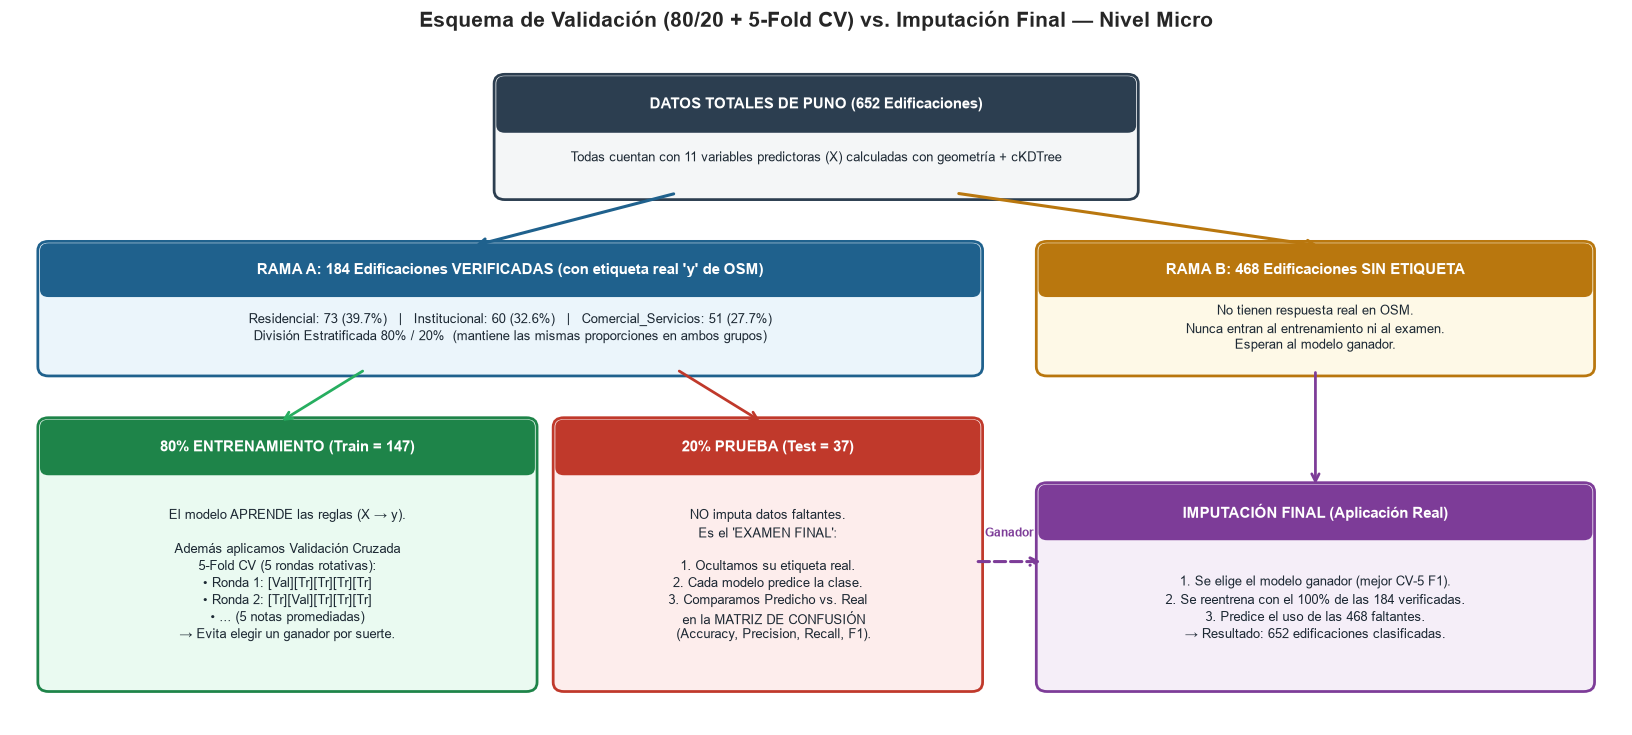

Figura guardada en: figures/02_flujo_validacion_micro.png


In [6]:
# Preparación de conjuntos Train/Test (80/20 estratificado) y 5-Fold CV
X = df_labeled[FEATURES].copy()
le = LabelEncoder()
y = le.fit_transform(df_labeled['clase_uso'])
clases_nombres = list(le.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Mapeo numérico de clases:", dict(enumerate(clases_nombres)))
print(f"Total verificadas: {len(X)}  ->  Train (80%): {len(X_train)}  |  Test (20%): {len(X_test)}")
print(f"Sin etiqueta en OSM (imputación final): {b_utm['clase_uso'].isna().sum()}")

# --- DIAGRAMA VISUAL DEL FLUJO DE VALIDACIÓN E IMPUTACIÓN (300 DPI) ---
fig, ax = plt.subplots(figsize=(15, 6.8))
ax.set_xlim(0, 15)
ax.set_ylim(0, 7.2)
ax.axis('off')

def caja(x, y, w, h, titulo, texto, bg, edge, title_color='white', hdr_h=0.55):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1", facecolor=bg, edgecolor=edge, linewidth=1.8))
    ax.add_patch(FancyBboxPatch((x, y + h - hdr_h), w, hdr_h, boxstyle="round,pad=0.08", facecolor=edge, edgecolor='none'))
    ax.text(x + w/2, y + h - hdr_h/2, titulo, color=title_color, fontsize=9.8, fontweight='bold', ha='center', va='center')
    ax.text(x + w/2, y + (h - hdr_h)/2, texto, color='#1c2833', fontsize=8.8, ha='center', va='center', linespacing=1.35)

caja(4.6, 5.75, 5.8, 1.15, "DATOS TOTALES DE PUNO (652 Edificaciones)",
     "Todas cuentan con 11 variables predictoras (X) calculadas con geometría + cKDTree",
     '#f4f6f7', '#2c3e50', hdr_h=0.45)

ax.annotate('', xy=(4.3, 5.15), xytext=(6.2, 5.72), arrowprops=dict(arrowstyle='->', lw=2.0, color='#1f618d'))
ax.annotate('', xy=(12.2, 5.15), xytext=(8.8, 5.72), arrowprops=dict(arrowstyle='->', lw=2.0, color='#b9770e'))

caja(0.35, 3.85, 8.6, 1.25, "RAMA A: 184 Edificaciones VERIFICADAS (con etiqueta real 'y' de OSM)",
     "Residencial: 73 (39.7%)   |   Institucional: 60 (32.6%)   |   Comercial_Servicios: 51 (27.7%)\nDivisión Estratificada 80% / 20%  (mantiene las mismas proporciones en ambos grupos)",
     '#ebf5fb', '#1f618d', hdr_h=0.42)

ax.annotate('', xy=(2.5, 3.25), xytext=(3.3, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#27ae60'))
ax.annotate('', xy=(7.0, 3.25), xytext=(6.2, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#c0392b'))

caja(0.35, 0.45, 4.45, 2.75, "80% ENTRENAMIENTO (Train = 147)",
     "El modelo APRENDE las reglas (X → y).\n\nAdemás aplicamos Validación Cruzada\n5-Fold CV (5 rondas rotativas):\n• Ronda 1: [Val][Tr][Tr][Tr][Tr]\n• Ronda 2: [Tr][Val][Tr][Tr][Tr]\n• ... (5 notas promediadas)\n→ Evita elegir un ganador por suerte.",
     '#eafaf1', '#1e8449', hdr_h=0.44)

caja(5.15, 0.45, 3.8, 2.75, "20% PRUEBA (Test = 37)",
     "NO imputa datos faltantes.\nEs el 'EXAMEN FINAL':\n\n1. Ocultamos su etiqueta real.\n2. Cada modelo predice la clase.\n3. Comparamos Predicho vs. Real\n   en la MATRIZ DE CONFUSIÓN\n   (Accuracy, Precision, Recall, F1).",
     '#fdedec', '#c0392b', hdr_h=0.44)

caja(9.65, 3.85, 5.0, 1.25, "RAMA B: 468 Edificaciones SIN ETIQUETA",
     "No tienen respuesta real en OSM.\nNunca entran al entrenamiento ni al examen.\nEsperan al modelo ganador.",
     '#fef9e7', '#b9770e', hdr_h=0.42)

ax.annotate('', xy=(12.15, 2.55), xytext=(12.15, 3.82), arrowprops=dict(arrowstyle='->', lw=1.8, color='#7d3c98'))
ax.annotate('', xy=(9.62, 1.75), xytext=(8.98, 1.75), arrowprops=dict(arrowstyle='->', lw=2.0, color='#7d3c98', ls='--'))
ax.text(9.30, 2.02, "Ganador", fontsize=8, fontweight='bold', color='#7d3c98', ha='center')

caja(9.65, 0.45, 5.0, 2.05, "IMPUTACIÓN FINAL (Aplicación Real)",
     "1. Se elige el modelo ganador (mejor CV-5 F1).\n2. Se reentrena con el 100% de las 184 verificadas.\n3. Predice el uso de las 468 faltantes.\n→ Resultado: 652 edificaciones clasificadas.",
     '#f5eef8', '#7d3c98', hdr_h=0.44)

plt.suptitle("Esquema de Validación (80/20 + 5-Fold CV) vs. Imputación Final — Nivel Micro", fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "02_flujo_validacion_micro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/02_flujo_validacion_micro.png")

## 5. Respaldo Matemático y Entrenamiento de los 4 Modelos Obligatorios

A continuación se resume la **matemática exacta que respalda cada uno de los 4 algoritmos** utilizados en este proyecto:

### 1. `DecisionTreeClassifier` — Árbol de Decisión Simple (**Gini** vs. **Entropía**)
El árbol particiona el espacio recursivamente eligiendo en cada nodo $t$ la variable y umbral que **maximizan la Ganancia de Información (reducción de impureza)**:
$$IG(t, f) = I(t) - \left(\frac{N_{\text{izq}}}{N}\, I(t_{\text{izq}}) + \frac{N_{\text{der}}}{N}\, I(t_{\text{der}})\right)$$
donde $p_k$ es la proporción de muestras de la clase $k$ en el nodo, y la impureza $I(t)$ se mide con uno de dos criterios:
* **Impureza de Gini:** $$G(t) = 1 - \sum_{k=1}^{K} p_k^2$$ *(vale $0$ si el nodo es puro; cálculo cuadrático rápido).*
* **Entropía de Shannon:** $$H(t) = -\sum_{k=1}^{K} p_k \log_2(p_k)$$ *(mide el desorden en bits; usa logaritmos).*

### 2. `RandomForestClassifier` — Ensamble *Bagging* (Árboles en Paralelo)
Entrena $B = 200$ árboles independientes en paralelo, cada uno sobre una muestra aleatoria con reemplazo (*Bootstrap*) y evaluando solo $m \approx \sqrt{p}$ variables por corte para decorrelacionar los árboles. La decisión final se obtiene por **votación / promedio de probabilidades**:
$$\hat{y}(x) = \arg\max_{k} \; \frac{1}{B} \sum_{b=1}^{B} P_b(y = k \mid x)$$
**Efecto matemático:** si cada árbol tiene varianza $\sigma^2$ y correlación promedio $\rho$ entre pares, la varianza del bosque se reduce a $\rho\sigma^2 + \frac{1 - \rho}{B}\sigma^2$, controlando el *overfitting* del árbol individual.

### 3. `XGBClassifier` — *XGBoost* (*Gradient Boosting* Regularizado, crecimiento *Level-wise*)
A diferencia de Random Forest, construye árboles **de forma secuencial**: cada nuevo árbol $f_t$ corrige los errores residuales del acumulado anterior, ponderado por la tasa de aprendizaje $\eta$:
$$\hat{y}_i^{(t)} = \hat{y}_i^{(t-1)} + \eta \, f_t(x_i)$$
Minimiza una función objetivo regularizada usando **expansión de Taylor de segundo orden** (gradiente $g_i = \partial_{\hat{y}} l$ y hessiano $h_i = \partial^2_{\hat{y}} l$):
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^{n} \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t(x_i)^2 \right] + \gamma T + \frac{1}{2}\lambda \sum_{j=1}^{T} w_j^2$$
De aquí surge el **peso óptimo de cada hoja** $w_j^*$ y la **ganancia de cada división**:
$$w_j^* = -\frac{\sum_{i \in I_j} g_i}{\sum_{i \in I_j} h_i + \lambda}, \qquad \text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma$$
XGBoost crece **por niveles completos (*level-wise*)**, manteniendo árboles equilibrados.

### 4. `LGBMClassifier` — *LightGBM* (Histogramas + Crecimiento *Leaf-wise*)
Comparte el mismo principio matemático de gradiente y hessiano ($g_i, h_i$) sobre la pérdida *multi-logloss*, pero incorpora dos optimizaciones algorítmicas clave:
1. **Agrupamiento en histogramas (*Binning*):** discretiza variables continuas en cubetas para evaluar cortes en $O(\text{bins})$ en vez de ordenar todos los datos en $O(N \log N)$, acelerando drásticamente el entrenamiento.
2. **Crecimiento por hojas (*Leaf-wise*):** en vez de dividir todo un nivel entero, busca globalmente la única hoja $j^*$ que aporta la mayor ganancia y la divide primero:
$$j^* = \arg\max_{j \in \text{hojas}} \; \text{Gain}(j)$$
Esto permite alcanzar menor error con menos nodos, generando árboles asimétricos controlados por `num_leaves` y `max_depth`.

### Paso 5.1: Experimento de Poda (`max_depth`) — Gini vs. Entropía

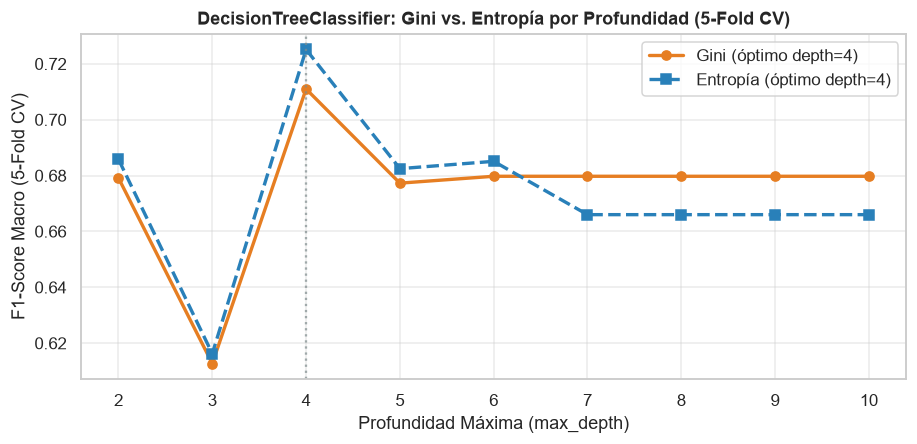

In [7]:
profundidades = range(2, 11)
scores_gini = []
scores_entropy = []

for d in profundidades:
    dt_g = DecisionTreeClassifier(criterion='gini', max_depth=d, min_samples_leaf=3, random_state=42)
    dt_e = DecisionTreeClassifier(criterion='entropy', max_depth=d, min_samples_leaf=3, random_state=42)
    scores_gini.append(cross_val_score(dt_g, X_train, y_train, cv=cv, scoring='f1_macro').mean())
    scores_entropy.append(cross_val_score(dt_e, X_train, y_train, cv=cv, scoring='f1_macro').mean())

mejor_d_gini = list(profundidades)[int(np.argmax(scores_gini))]
mejor_d_entropy = list(profundidades)[int(np.argmax(scores_entropy))]

plt.figure(figsize=(8.5, 4.2))
plt.plot(profundidades, scores_gini, marker='o', linewidth=2.2, color='#e67e22', label=f'Gini (óptimo depth={mejor_d_gini})')
plt.plot(profundidades, scores_entropy, marker='s', linewidth=2.2, linestyle='--', color='#2980b9', label=f'Entropía (óptimo depth={mejor_d_entropy})')
plt.axvline(mejor_d_gini, color='#7f8c8d', linestyle=':', alpha=0.7)
plt.title("DecisionTreeClassifier: Gini vs. Entropía por Profundidad (5-Fold CV)", fontweight='bold')
plt.xlabel("Profundidad Máxima (max_depth)")
plt.ylabel("F1-Score Macro (5-Fold CV)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### Paso 5.2: Entrenamiento y Tabla Comparativa de los 4 Modelos (5 configuraciones)

In [8]:
modelos = {
    'DecisionTree (Gini)': DecisionTreeClassifier(
        criterion='gini', max_depth=mejor_d_gini, min_samples_leaf=3, random_state=42
    ),
    'DecisionTree (Entropía)': DecisionTreeClassifier(
        criterion='entropy', max_depth=mejor_d_entropy, min_samples_leaf=3, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, eval_metric='mlogloss', random_state=42
    ),
    'LightGBM': LGBMClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.05,
        num_leaves=15, min_child_samples=10, random_state=42, verbose=-1
    )
}

resultados = []
predicciones_test = {}
modelos_entrenados = {}

for nombre, modelo in modelos.items():
    cv_f1 = cross_val_score(modelo, X, y, cv=cv, scoring='f1_macro').mean()
    cv_acc = cross_val_score(modelo, X, y, cv=cv, scoring='accuracy').mean()

    t0 = time.perf_counter()
    modelo.fit(X_train, y_train)
    tiempo_ms = (time.perf_counter() - t0) * 1000

    y_pred = modelo.predict(X_test)
    predicciones_test[nombre] = y_pred
    modelos_entrenados[nombre] = modelo

    resultados.append({
        'Modelo': nombre,
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Precision (Macro)': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Test Recall (Macro)': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Test F1 (Macro)': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'CV-5 Accuracy': cv_acc,
        'CV-5 F1 (Macro)': cv_f1,
        'Tiempo Train (ms)': tiempo_ms
    })

df_resultados_micro = pd.DataFrame(resultados).sort_values(by='CV-5 F1 (Macro)', ascending=False)
df_resultados_micro.to_csv(DIR_DATA_PUNO / "resultados_micro_modelos.csv", index=False)
display(df_resultados_micro.round(4))

,Modelo,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro),CV-5 Accuracy,CV-5 F1 (Macro),Tiempo Train (ms)
4,LightGBM,0.8108,0.7879,0.7889,0.7874,0.7667,0.7496,45.2123
2,Random Forest,0.8378,0.8681,0.8333,0.8115,0.7664,0.7465,498.4390
3,XGBoost,0.7838,0.7676,0.7667,0.7545,0.7395,0.7160,254.3554
1,DecisionTree (Entropía),0.6757,0.6347,0.6500,0.6204,0.7009,0.6744,2.2713
0,DecisionTree (Gini),0.8108,0.8125,0.8000,0.7831,0.6793,0.6517,2.1158


## 6. Visualización Completa de los Árboles en los 4 Modelos (Sin Recortes `(...)`)

Para comprender y exponer con total claridad cómo decide cada algoritmo, graficamos **cada árbol por separado y de forma 100% completa desde la raíz hasta todas sus hojas terminales** (sin truncar niveles):
* **6.1. `DecisionTree (Gini)` completo** (profundidad 4, 11 hojas).
* **6.2. `DecisionTree (Entropía)` completo** (profundidad 4, 11 hojas).
* **6.3. `Random Forest` completo (Árbol #1 y Árbol #200):** mostramos el **primer** y el **último árbol (#200)** del bosque completos hasta todas sus hojas. *(Nota importante para la exposición: en Random Forest el Árbol #200 NO reemplaza al Árbol #1; los 200 árboles conviven en paralelo y votan juntos por mayoría).*
* **6.4. `XGBoost` completo (Ronda 1 y Ronda Final #150):** mostramos el **árbol inicial** y el **último árbol** completos con todas sus hojas $w^*$, evidenciando el crecimiento *level-wise* y cómo en la ronda final los ajustes residuales se vuelven muy pequeños al converger el modelo.
* **6.5. `LightGBM` completo (Ronda 2 y Ronda Final #150):** mostramos el árbol inicial y el último árbol completos con todas sus hojas $w^*$, evidenciando su crecimiento asimétrico *leaf-wise*.

### 6.1. Modelo 1A — `DecisionTreeClassifier` (Criterio GINI — Árbol Completo)

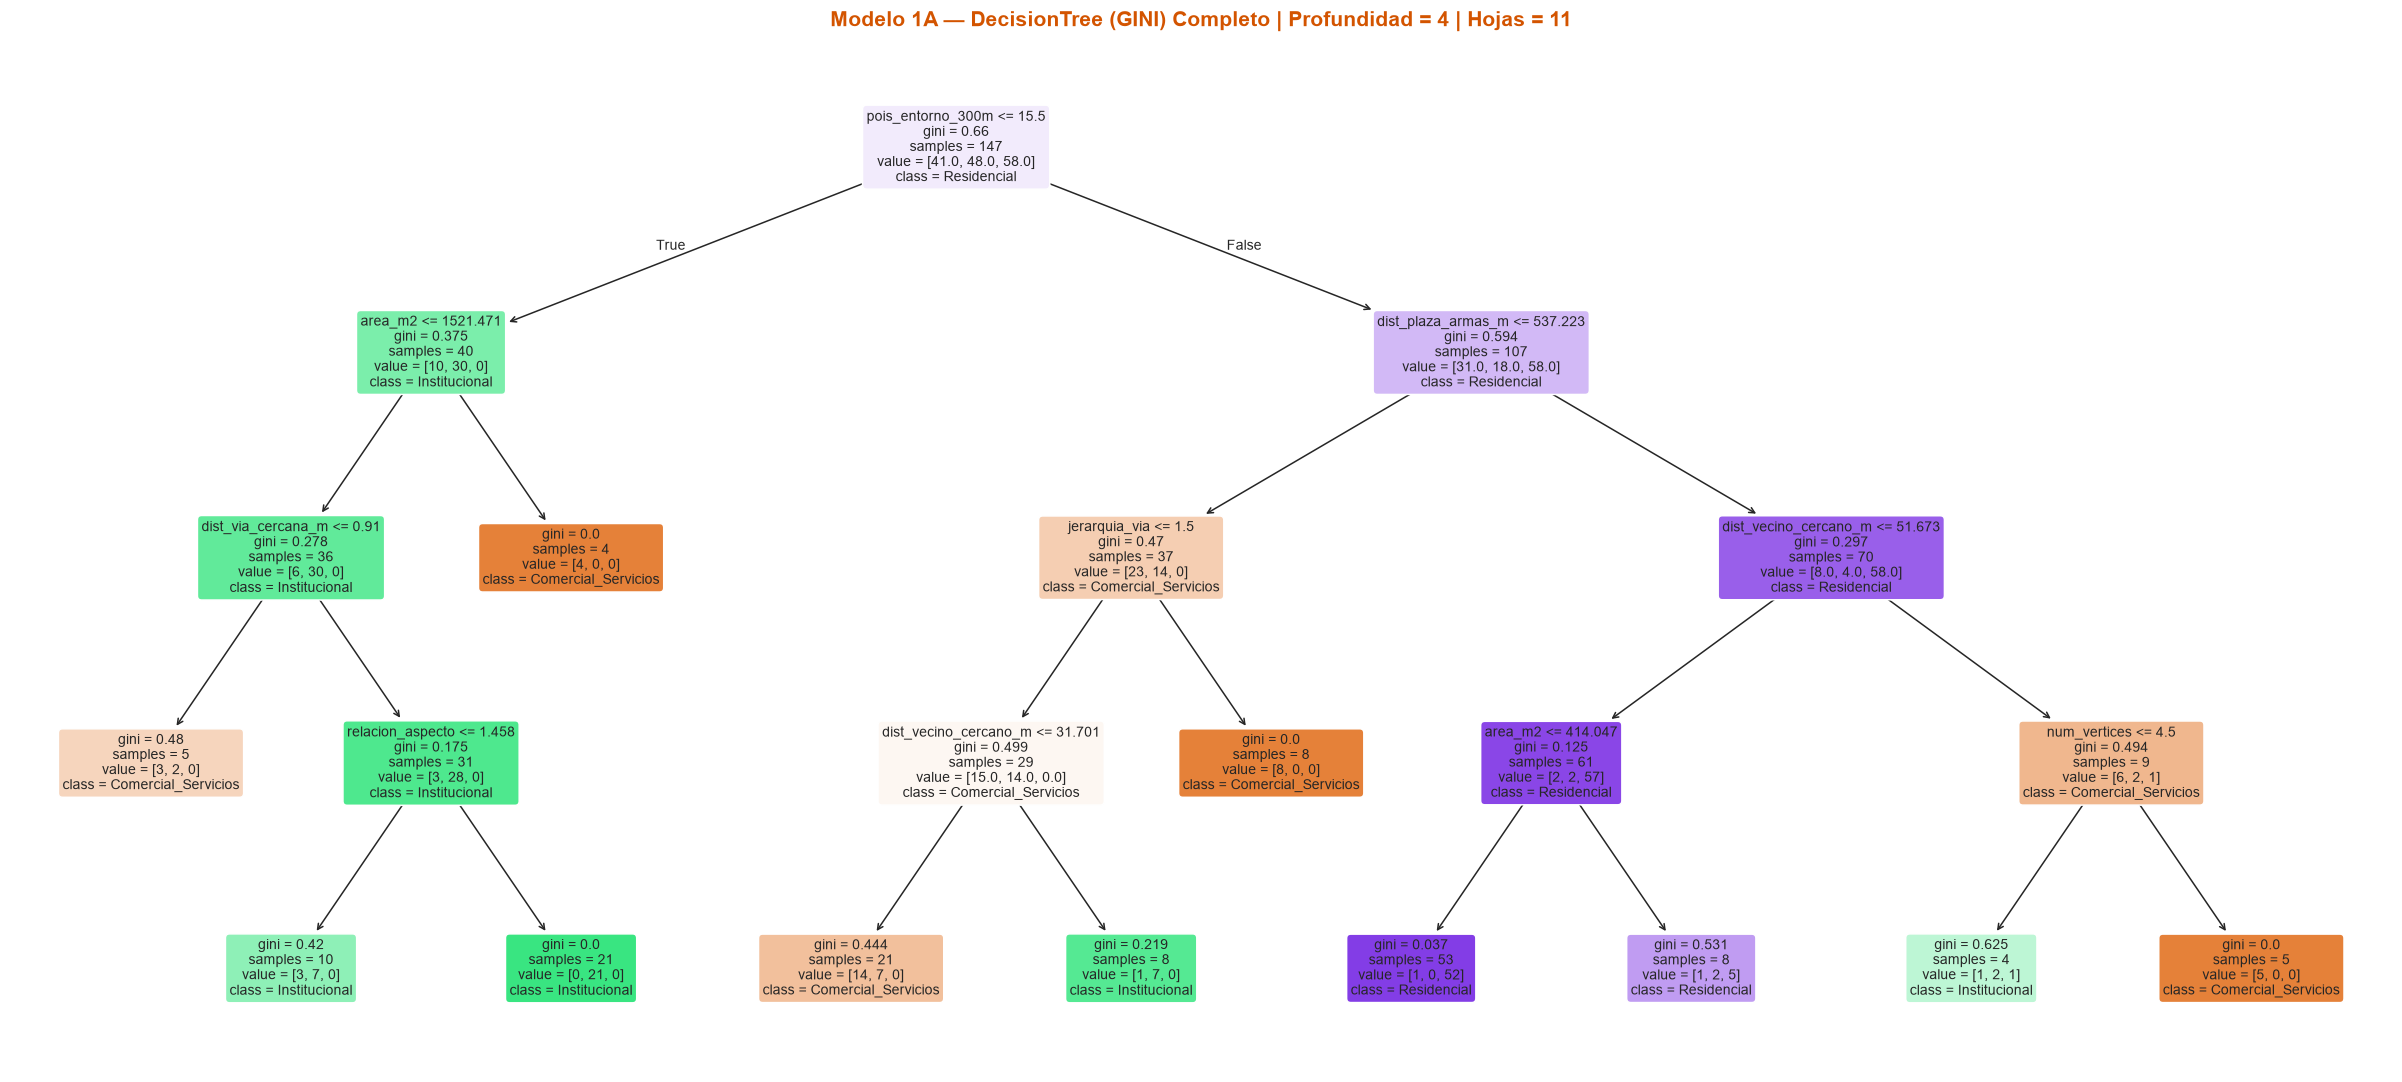

Figura guardada en: figures/02_arbol_gini_completo.png


In [9]:
dt_gini = modelos_entrenados['DecisionTree (Gini)']
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    dt_gini,
    feature_names=FEATURES,
    class_names=clases_nombres,
    filled=True, rounded=True, fontsize=9, ax=ax
)
ax.set_title(
    f"Modelo 1A — DecisionTree (GINI) Completo | Profundidad = {dt_gini.get_depth()} | Hojas = {dt_gini.get_n_leaves()}",
    fontsize=14, fontweight='bold', color='#d35400', pad=12
)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "02_arbol_gini_completo.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/02_arbol_gini_completo.png")

### 6.2. Modelo 1B — `DecisionTreeClassifier` (Criterio ENTROPÍA — Árbol Completo)

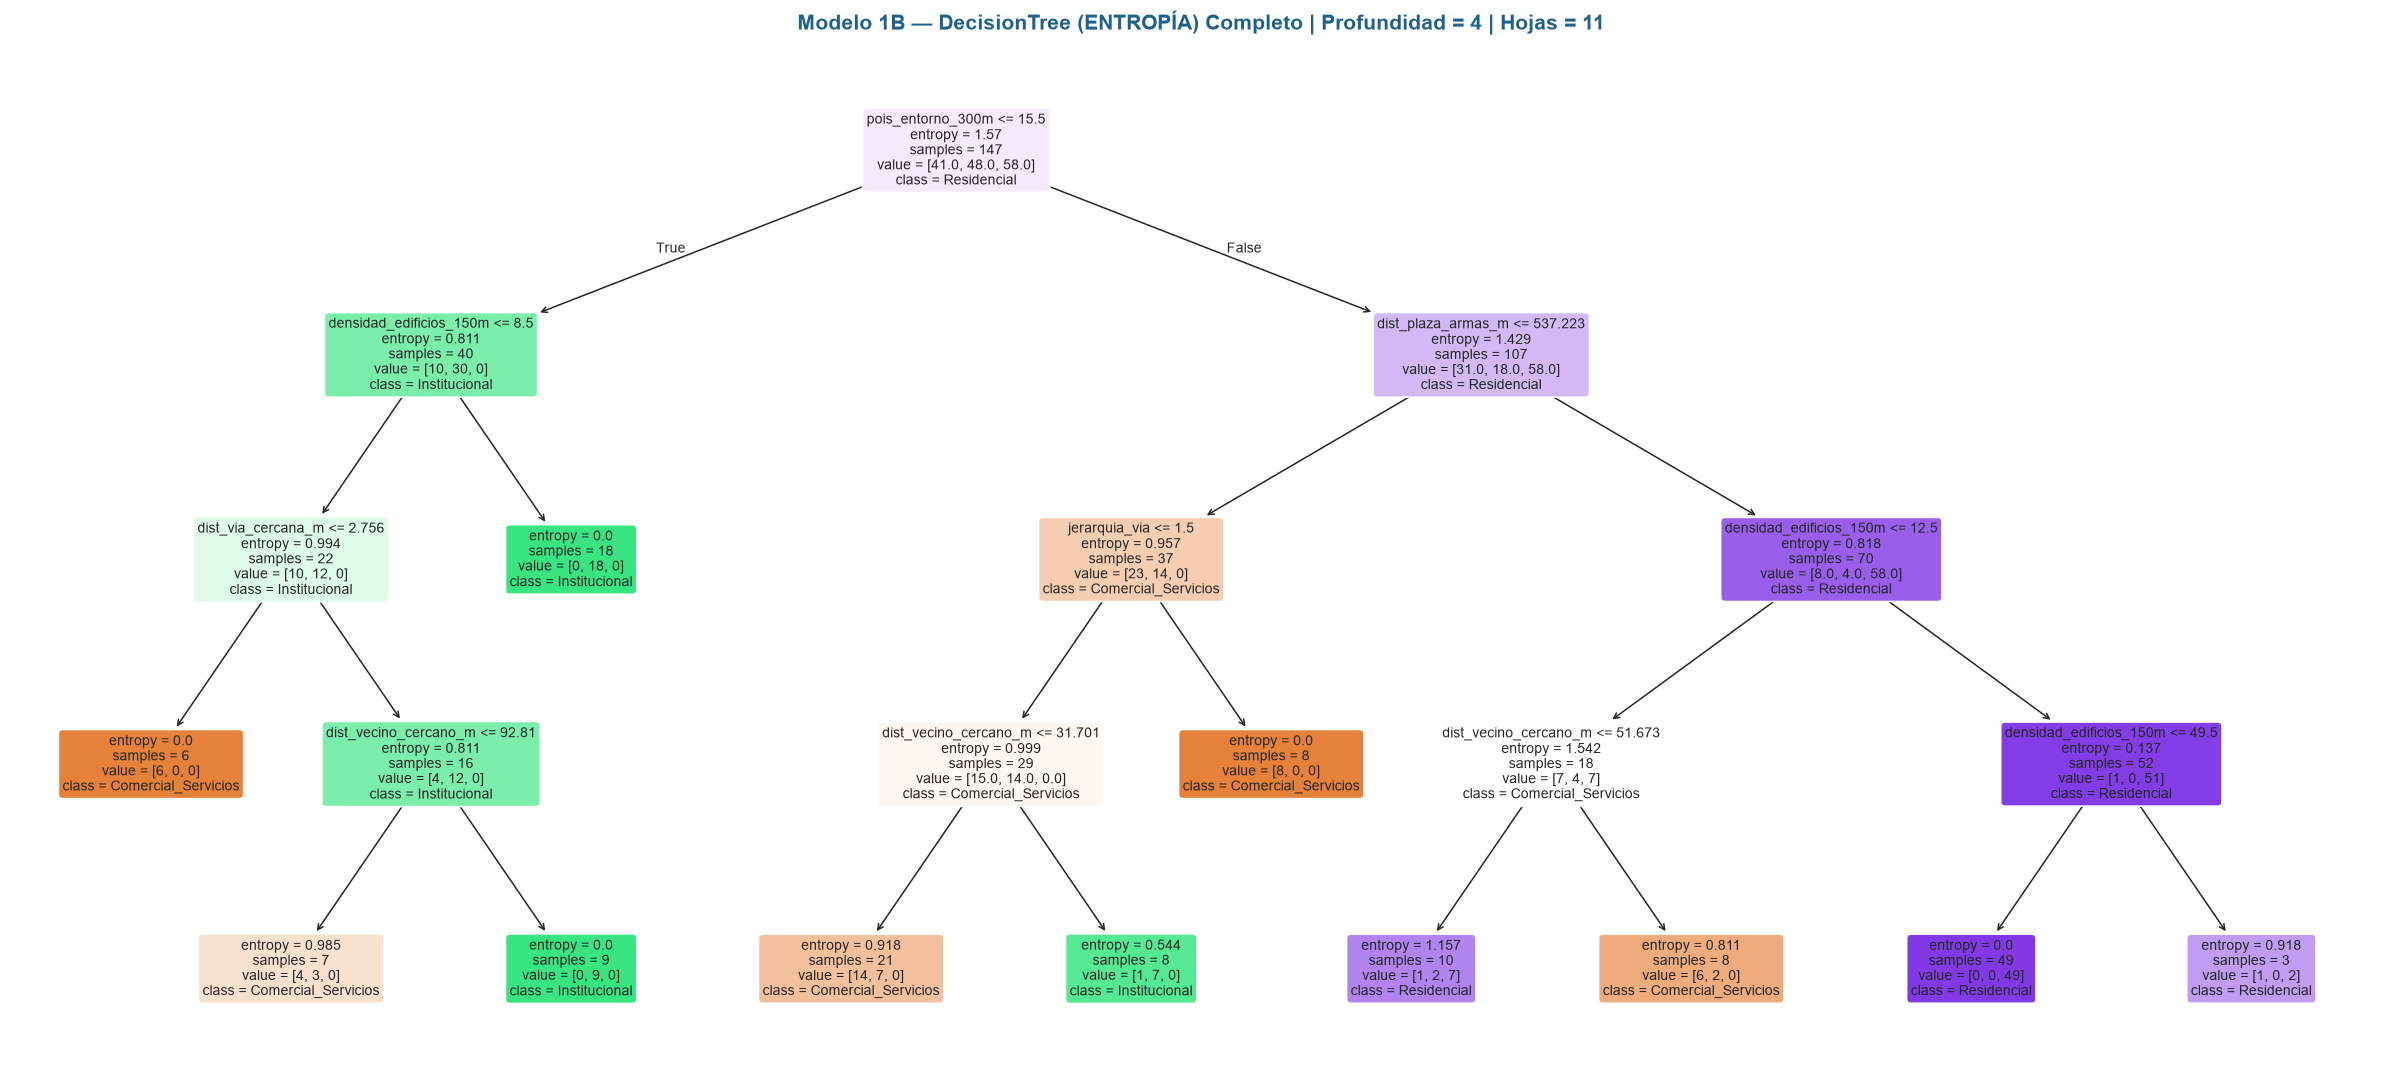

Figura guardada en: figures/02_arbol_entropia_completo.png


In [10]:
dt_ent = modelos_entrenados['DecisionTree (Entropía)']
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    dt_ent,
    feature_names=FEATURES,
    class_names=clases_nombres,
    filled=True, rounded=True, fontsize=9, ax=ax
)
ax.set_title(
    f"Modelo 1B — DecisionTree (ENTROPÍA) Completo | Profundidad = {dt_ent.get_depth()} | Hojas = {dt_ent.get_n_leaves()}",
    fontsize=14, fontweight='bold', color='#1f618d', pad=12
)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "02_arbol_entropia_completo.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/02_arbol_entropia_completo.png")

### 6.3. Modelo 2 — `RandomForestClassifier` (*Bagging*): Árbol #1 y Árbol #200 Completos

> **Detalle clave para explicar al ingeniero:** Random Forest entrena **200 árboles independientes en paralelo** (cada uno ve una muestra *Bootstrap* distinta). El **Árbol #200** es el último árbol generado del bosque, pero **todos los 200 árboles participan por igual en la votación final**.

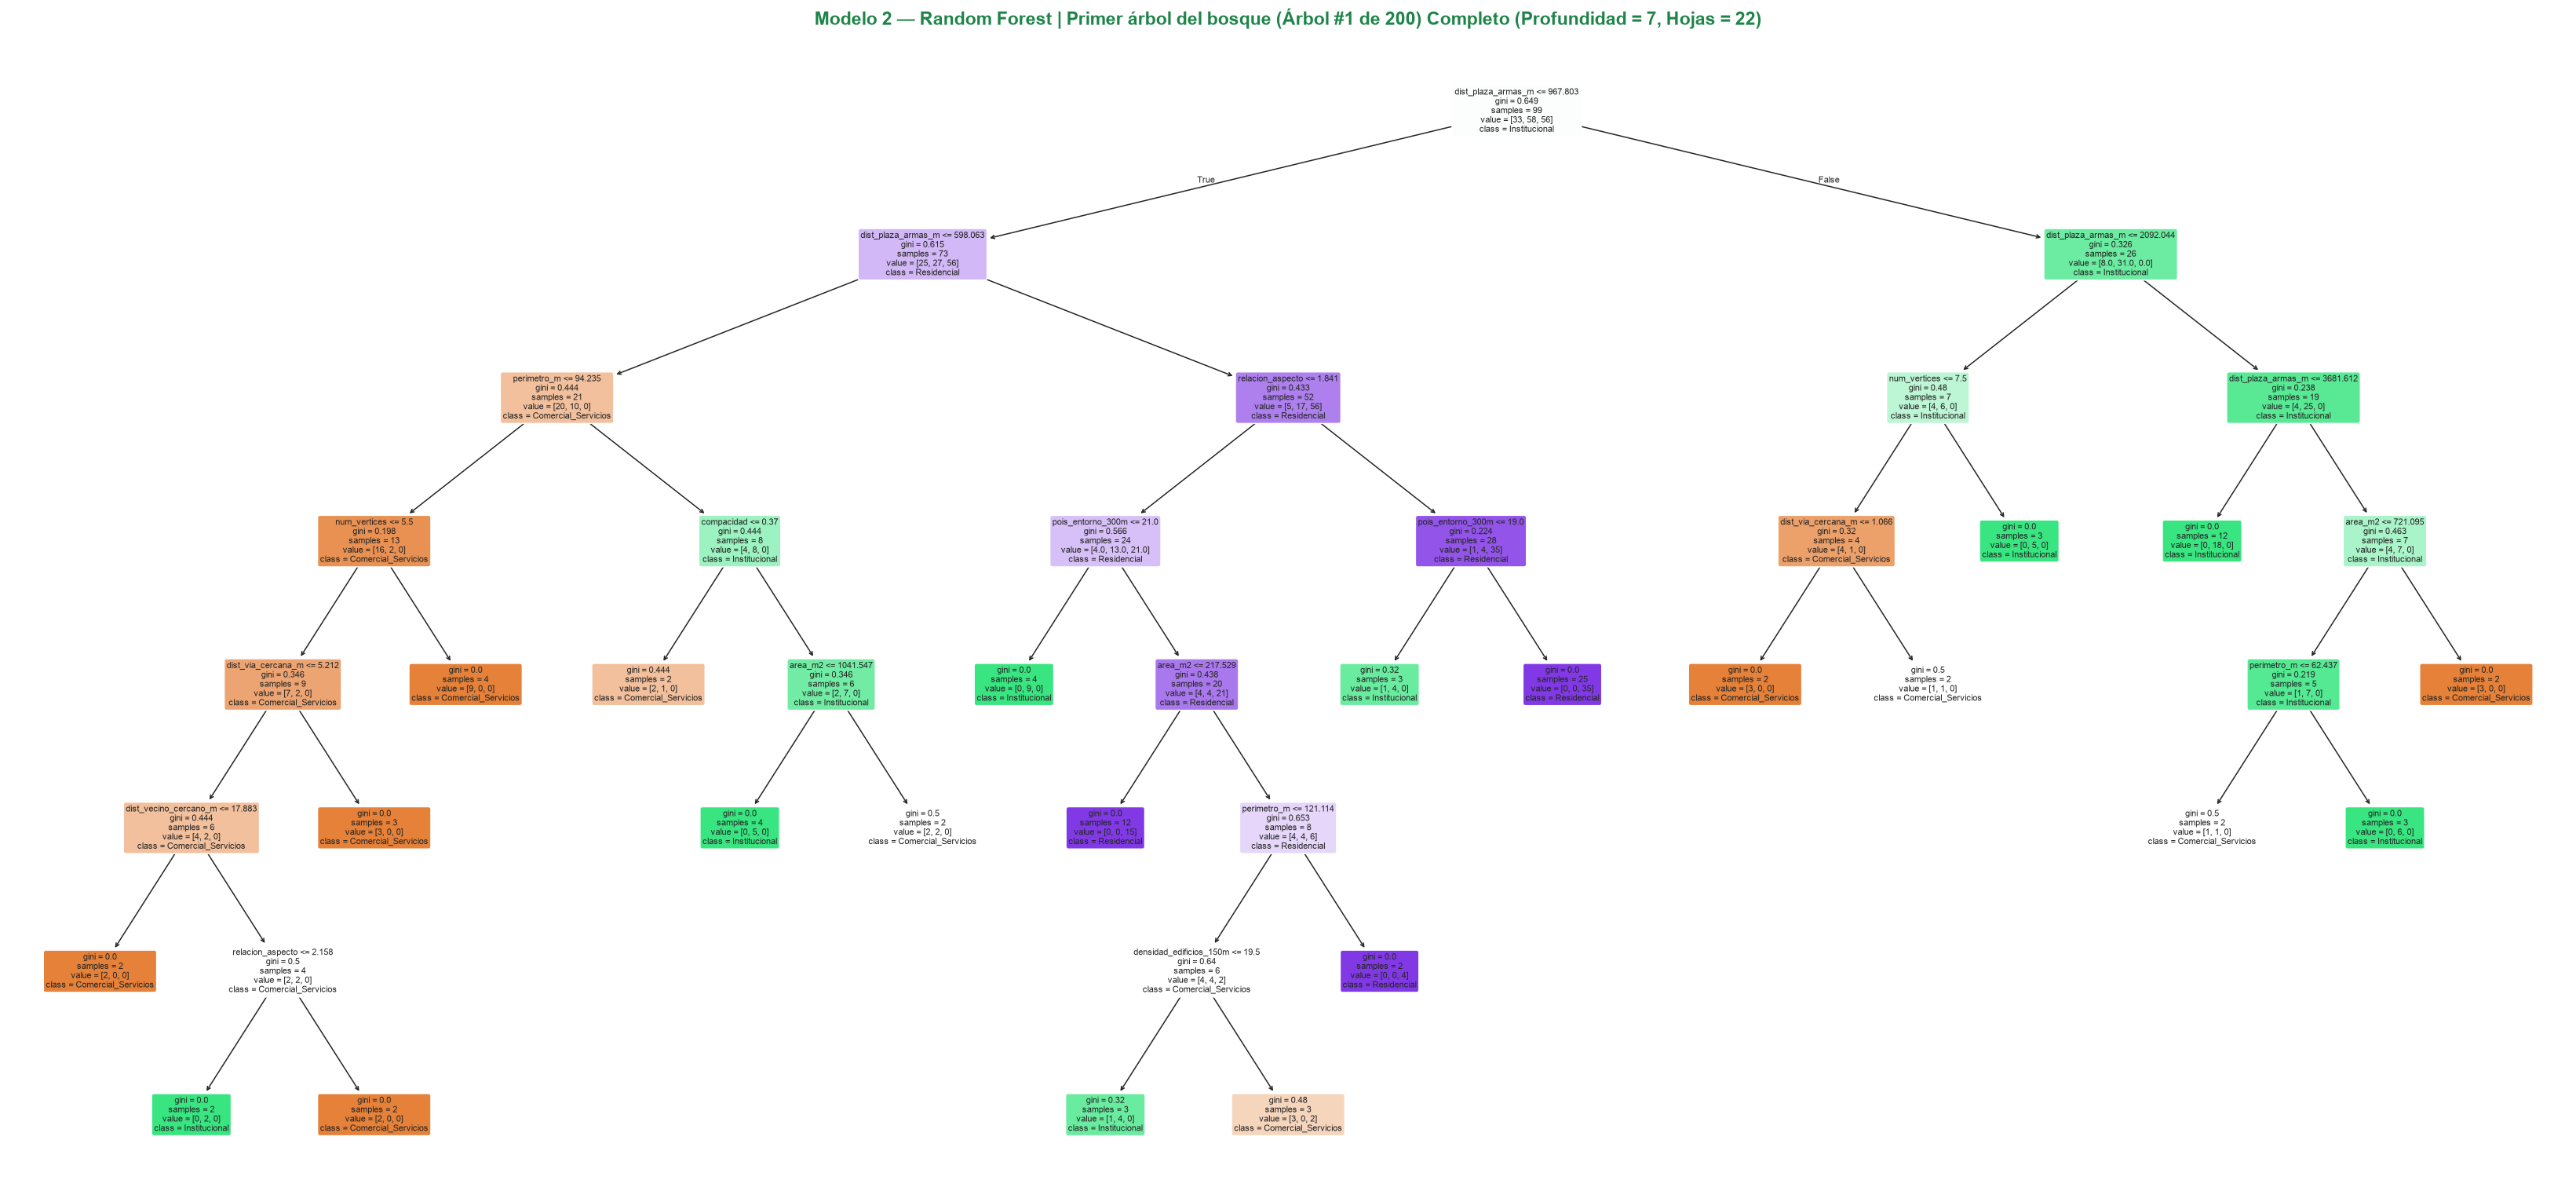

Figura guardada en: figures/02_arbol_rf_001_completo.png


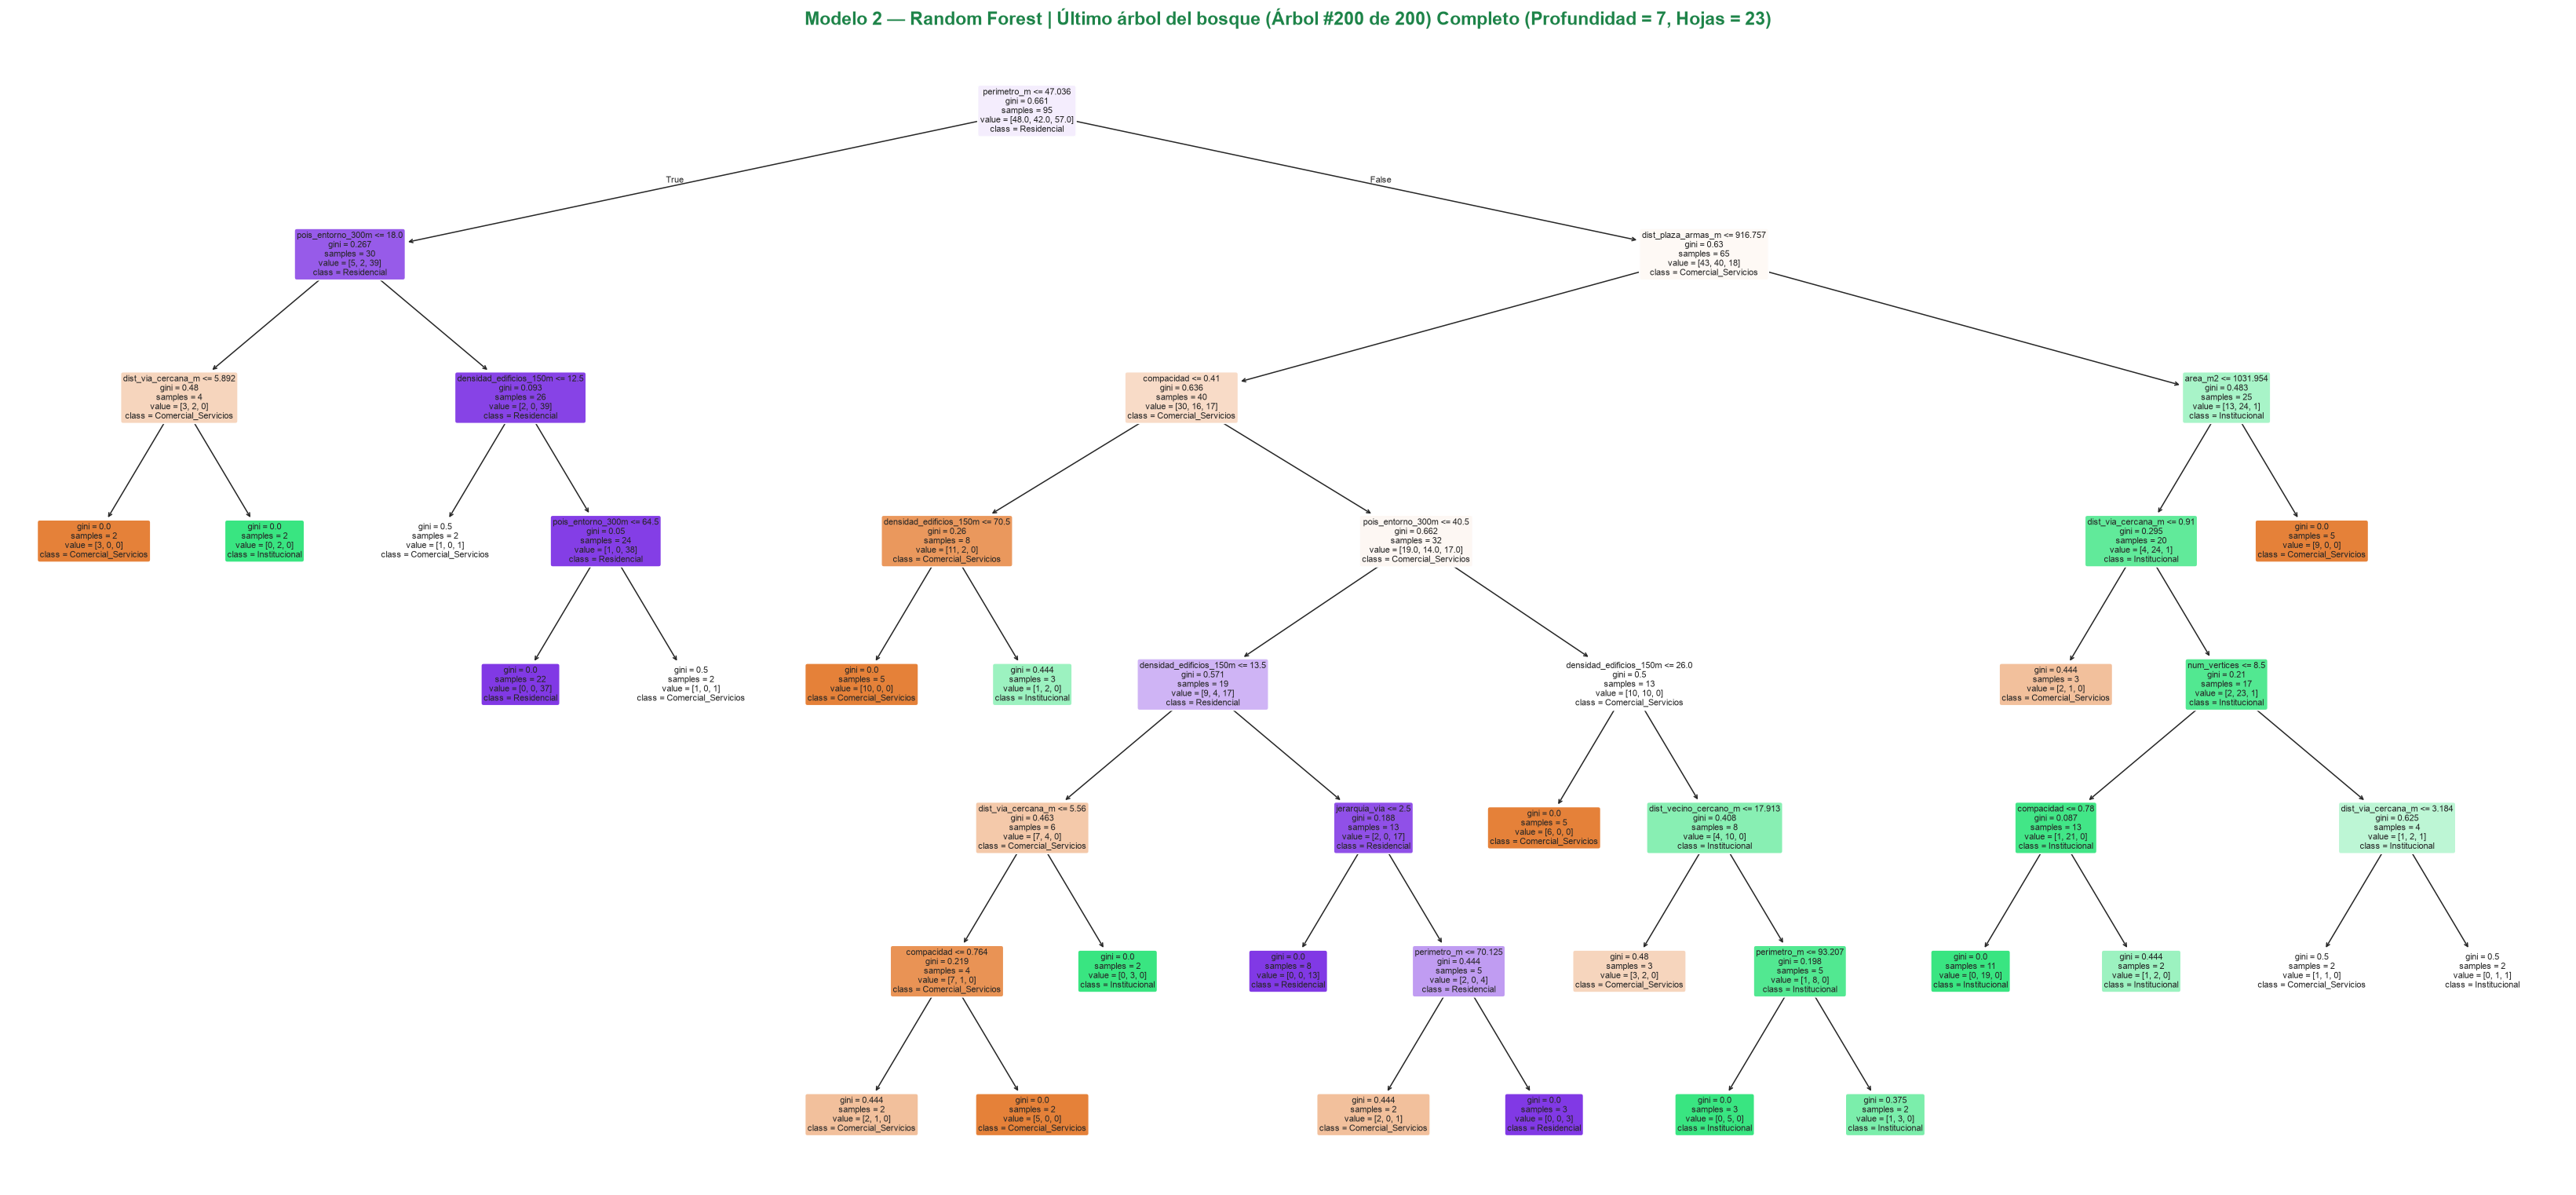

Figura guardada en: figures/02_arbol_rf_200_completo.png


In [11]:
rf_model = modelos_entrenados['Random Forest']

for idx_tree, fname, subtitulo in [
    (0,   "02_arbol_rf_001_completo.png", "Primer árbol del bosque (Árbol #1 de 200)"),
    (199, "02_arbol_rf_200_completo.png", "Último árbol del bosque (Árbol #200 de 200)")
]:
    est = rf_model.estimators_[idx_tree]
    fig, ax = plt.subplots(figsize=(30, 14))
    plot_tree(
        est,
        feature_names=FEATURES,
        class_names=clases_nombres,
        filled=True, rounded=True, fontsize=7, ax=ax
    )
    ax.set_title(
        f"Modelo 2 — Random Forest | {subtitulo} Completo (Profundidad = {est.get_depth()}, Hojas = {est.get_n_leaves()})",
        fontsize=15, fontweight='bold', color='#1e8449', pad=12
    )
    plt.tight_layout()
    plt.savefig(DIR_FIGURES / fname, bbox_inches='tight')
    plt.show()
    print(f"Figura guardada en: figures/{fname}")

### 6.4 y 6.5. Modelos 3 y 4 — `XGBoost` y `LightGBM` Completos (Inicio y Ronda Final #150)

A diferencia de Random Forest, en **Boosting** los árboles sí se construyen **en secuencia**: cada árbol corrige el error residual dejado por todos los anteriores. Por eso mostramos **completos (sin truncar ninguna hoja)**:
* **XGBoost:** Ronda 1 (correcciones grandes, 11 hojas) y **Ronda Final #150** (ajustes finos al converger, 6 hojas).
* **LightGBM:** Ronda 2 (crecimiento asimétrico *leaf-wise*, 8 hojas) y **Ronda Final #150** (ajustes finos, 7 hojas).

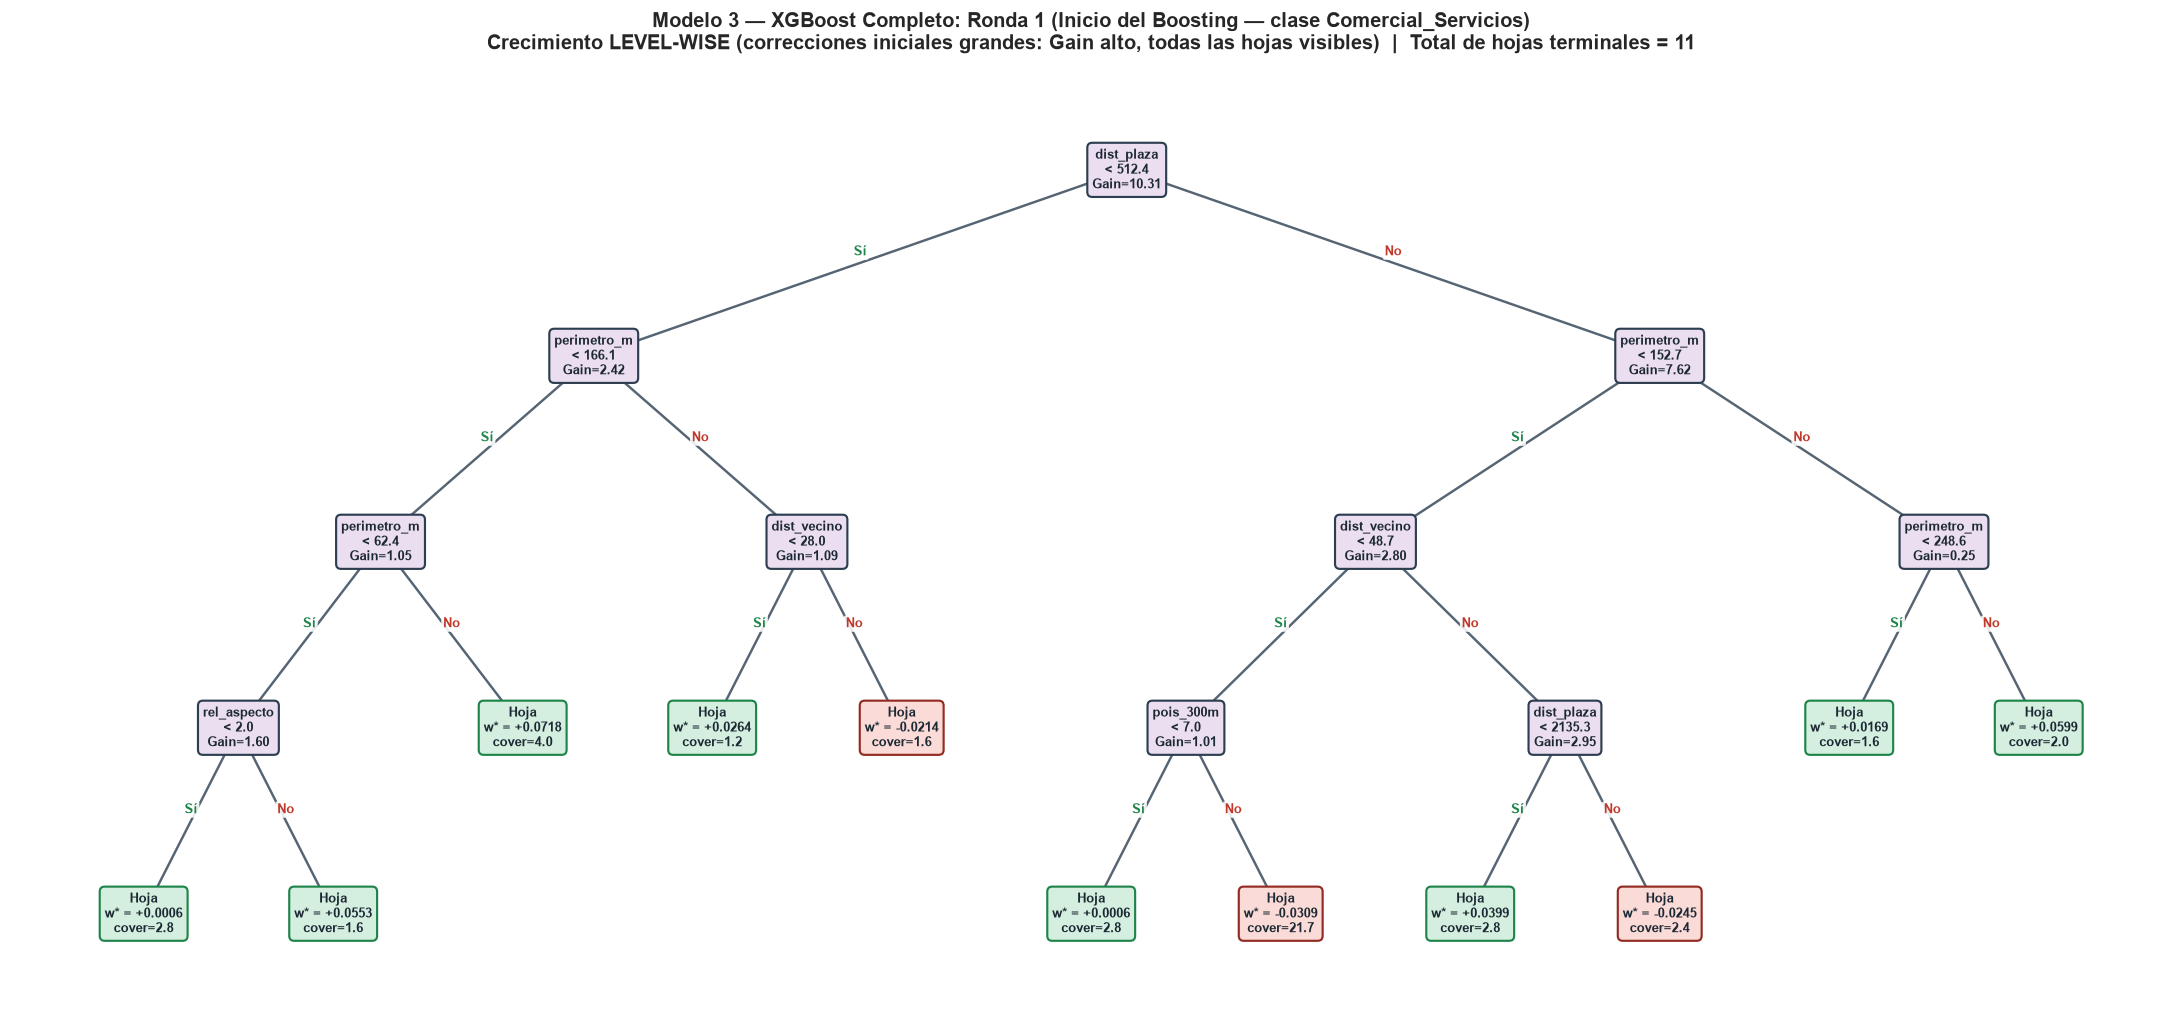

Figura guardada en: figures/02_arbol_xgboost_ronda1_completo.png


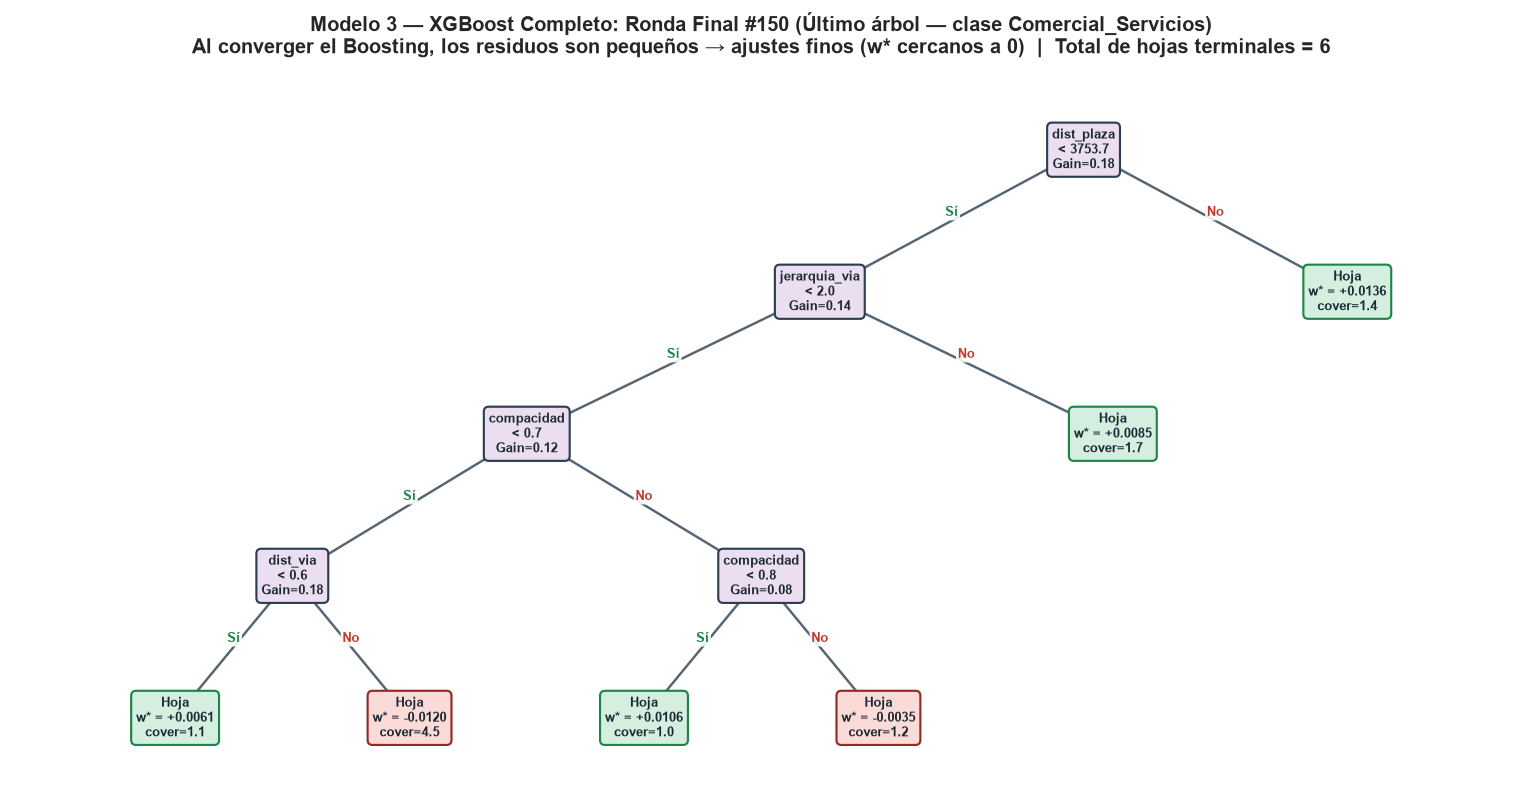

Figura guardada en: figures/02_arbol_xgboost_ronda150_completo.png


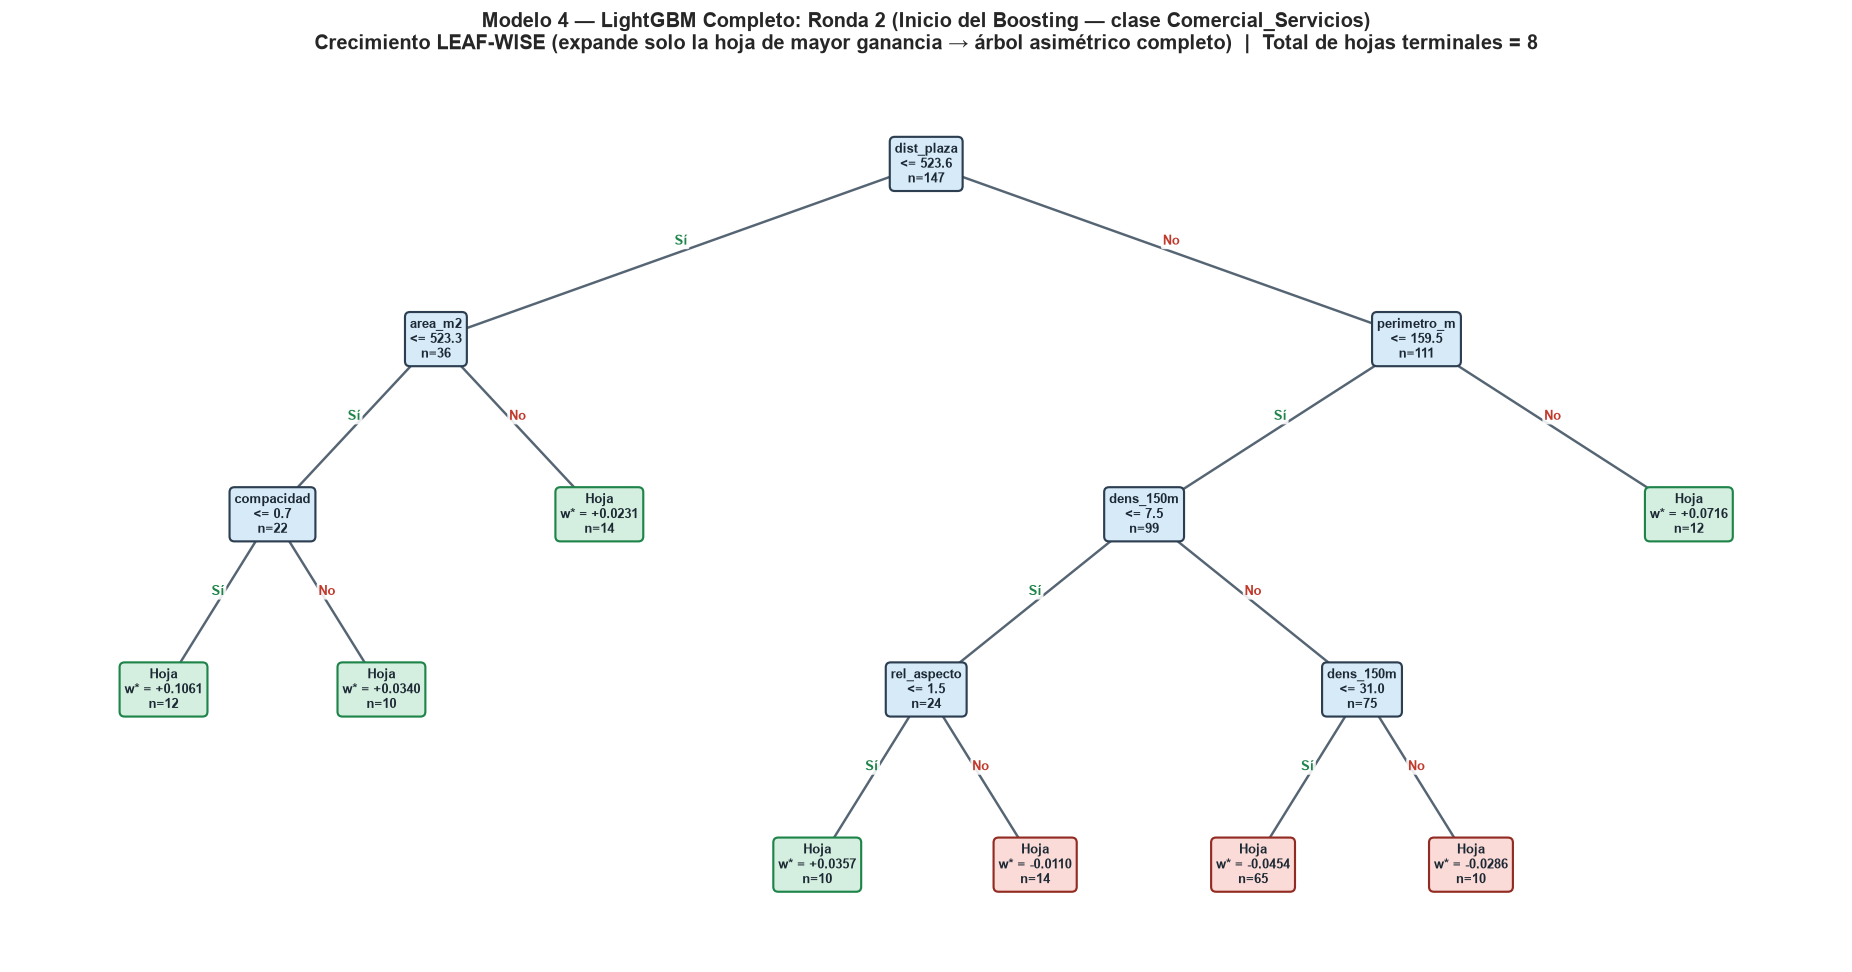

Figura guardada en: figures/02_arbol_lightgbm_ronda2_completo.png


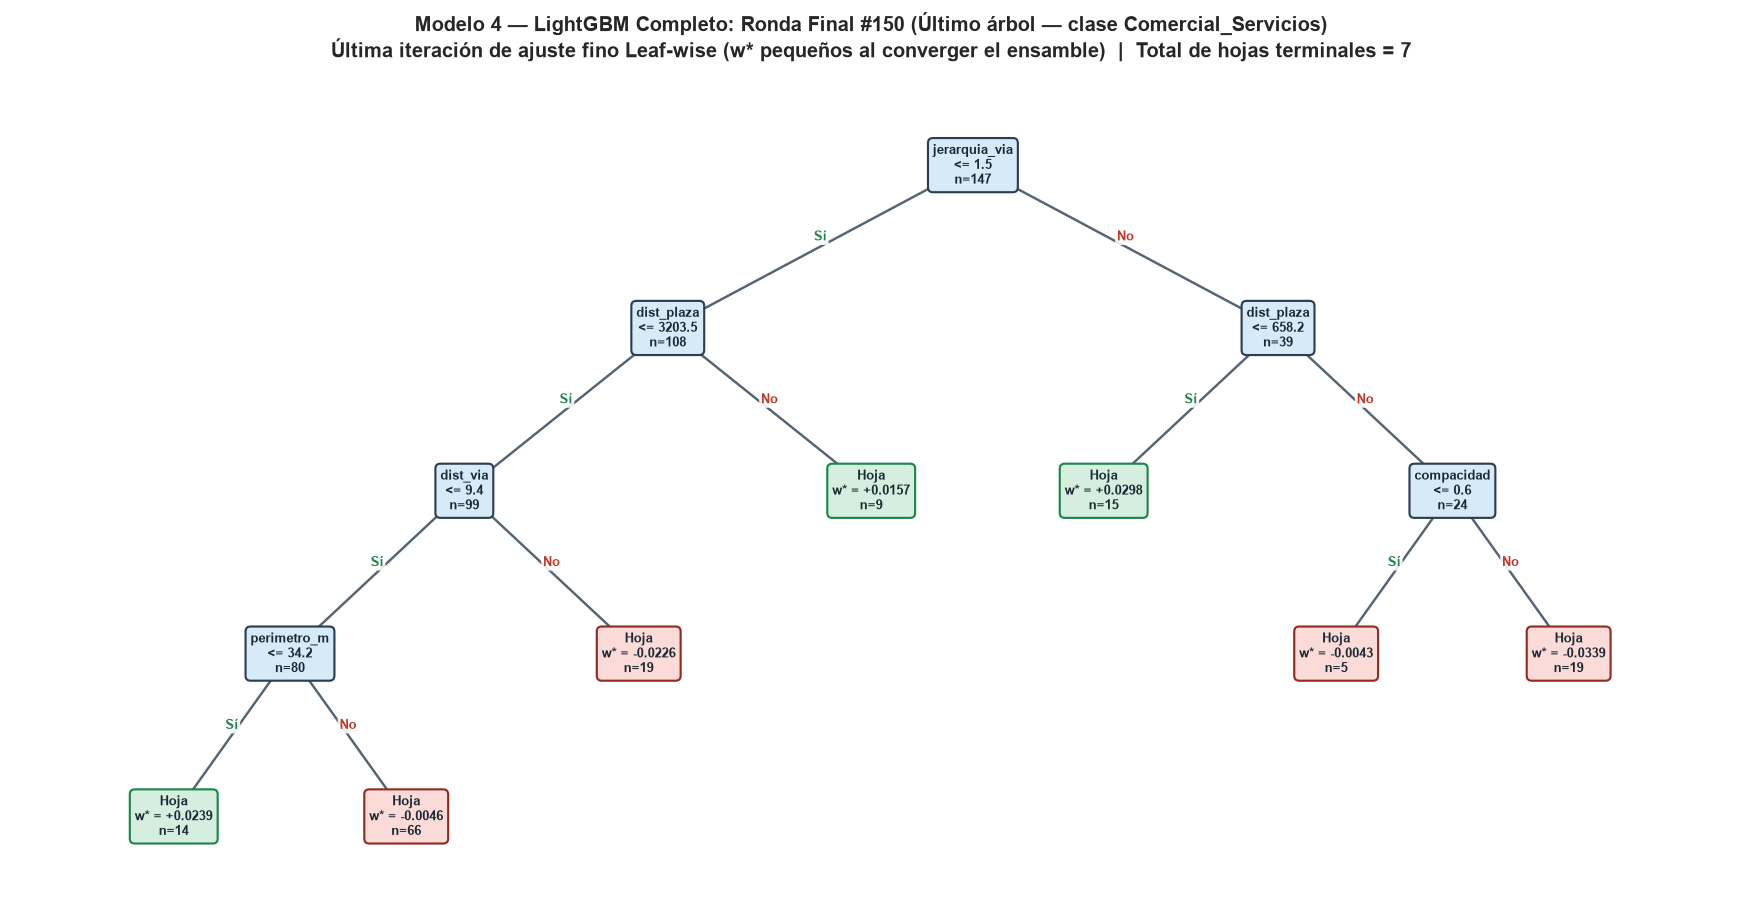

Figura guardada en: figures/02_arbol_lightgbm_ronda150_completo.png


In [12]:
# Renderizador completo en Matplotlib puro (100% compatible con Windows y Google Colab, sin Graphviz)
def acortar_nombre_var(s):
    return (
        str(s)
        .replace('dist_plaza_armas_m', 'dist_plaza')
        .replace('dist_vecino_cercano_m', 'dist_vecino')
        .replace('dist_via_cercana_m', 'dist_via')
        .replace('pois_entorno_300m', 'pois_300m')
        .replace('densidad_edificios_150m', 'dens_150m')
        .replace('relacion_aspecto', 'rel_aspecto')
    )

def extraer_arbol_xgb_completo(xgb_model, tree_idx=0):
    df_t = xgb_model.get_booster().trees_to_dataframe()
    sub = df_t[df_t['Tree'] == tree_idx].set_index('ID')
    root_id = f"{tree_idx}-0"

    def build(nid):
        row = sub.loc[nid]
        if row['Feature'] == 'Leaf':
            val = float(row['Gain'])
            lbl = f"Hoja\nw* = {val:+.4f}\ncover={row['Cover']:.1f}"
            return {'label': lbl, 'is_leaf': True, 'val': val, 'left': None, 'right': None}
        lbl = f"{acortar_nombre_var(row['Feature'])}\n< {float(row['Split']):.1f}\nGain={float(row['Gain']):.2f}"
        return {
            'label': lbl, 'is_leaf': False, 'val': 0.0,
            'left': build(row['Yes']),
            'right': build(row['No'])
        }
    return build(root_id)

def extraer_arbol_lgbm_completo(lgbm_model, tree_idx=3):
    df_t = lgbm_model.booster_.trees_to_dataframe()
    sub = df_t[df_t['tree_index'] == tree_idx].set_index('node_index')
    root_id = sub[sub['node_depth'] == 1].index[0]

    def build(nid):
        row = sub.loc[nid]
        if pd.isna(row['split_feature']):
            val = float(row['value'])
            lbl = f"Hoja\nw* = {val:+.4f}\nn={int(row['count'])}"
            return {'label': lbl, 'is_leaf': True, 'val': val, 'left': None, 'right': None}
        lbl = f"{acortar_nombre_var(row['split_feature'])}\n<= {float(row['threshold']):.1f}\nn={int(row['count'])}"
        return {
            'label': lbl, 'is_leaf': False, 'val': 0.0,
            'left': build(row['left_child']),
            'right': build(row['right_child'])
        }
    return build(root_id)

def dibujar_arbol_completo(root, titulo, subtitulo, color_nodo, fname, figsize=(19, 9)):
    coords = {}
    leaf_counter = [0]
    max_d = [0]

    def assign_pos(node, depth):
        max_d[0] = max(max_d[0], depth)
        if node['left'] is None and node['right'] is None:
            x = leaf_counter[0]
            leaf_counter[0] += 1
            coords[id(node)] = (x, -depth)
            return x
        xl = assign_pos(node['left'], depth + 1)
        xr = assign_pos(node['right'], depth + 1)
        x = (xl + xr) / 2.0
        coords[id(node)] = (x, -depth)
        return x

    assign_pos(root, 0)

    fig, ax = plt.subplots(figsize=figsize)
    def draw(node):
        x, y = coords[id(node)]
        for side, child, edge_lbl in [('L', node['left'], 'Sí'), ('R', node['right'], 'No')]:
            if child is not None:
                cx, cy = coords[id(child)]
                ax.plot([x, cx], [y, cy], color='#566573', linewidth=1.6, zorder=1)
                mx, my = (x + cx) / 2.0, (y + cy) / 2.0
                ax.text(mx, my + 0.06, edge_lbl, fontsize=8.5, fontweight='bold',
                        color='#1e8449' if side == 'L' else '#c0392b', ha='center', va='center',
                        bbox=dict(boxstyle='round,pad=0.14', facecolor='white', edgecolor='none', alpha=0.88))
                draw(child)

        if node['is_leaf']:
            fc = '#d4efdf' if node['val'] >= 0 else '#fadbd8'
            ec = '#1e8449' if node['val'] >= 0 else '#922b21'
        else:
            fc = color_nodo
            ec = '#2c3e50'
        ax.text(
            x, y, node['label'], ha='center', va='center', fontsize=8.5, fontweight='bold', color='#1c2833',
            bbox=dict(boxstyle='round,pad=0.38', facecolor=fc, edgecolor=ec, linewidth=1.4), zorder=3
        )

    draw(root)
    ax.set_xlim(-0.7, leaf_counter[0] - 0.3)
    ax.set_ylim(-max_d[0] - 0.55, 0.55)
    ax.axis('off')
    ax.set_title(f"{titulo}\n{subtitulo}  |  Total de hojas terminales = {leaf_counter[0]}",
                 fontsize=13, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(DIR_FIGURES / fname, bbox_inches='tight')
    plt.show()
    print(f"Figura guardada en: figures/{fname}")

# --- MODELO 3: XGBOOST COMPLETO (RONDA 1 Y ÚLTIMA RONDA #150) ---
xgb_m = modelos_entrenados['XGBoost']
dibujar_arbol_completo(
    extraer_arbol_xgb_completo(xgb_m, tree_idx=0),
    "Modelo 3 — XGBoost Completo: Ronda 1 (Inicio del Boosting — clase Comercial_Servicios)",
    "Crecimiento LEVEL-WISE (correcciones iniciales grandes: Gain alto, todas las hojas visibles)",
    color_nodo='#ebdef0', fname="02_arbol_xgboost_ronda1_completo.png", figsize=(20, 9.5)
)
dibujar_arbol_completo(
    extraer_arbol_xgb_completo(xgb_m, tree_idx=447),
    "Modelo 3 — XGBoost Completo: Ronda Final #150 (Último árbol — clase Comercial_Servicios)",
    "Al converger el Boosting, los residuos son pequeños → ajustes finos (w* cercanos a 0)",
    color_nodo='#ebdef0', fname="02_arbol_xgboost_ronda150_completo.png", figsize=(14, 7.5)
)

# --- MODELO 4: LIGHTGBM COMPLETO (RONDA 2 Y ÚLTIMA RONDA #150) ---
lgbm_m = modelos_entrenados['LightGBM']
dibujar_arbol_completo(
    extraer_arbol_lgbm_completo(lgbm_m, tree_idx=3),
    "Modelo 4 — LightGBM Completo: Ronda 2 (Inicio del Boosting — clase Comercial_Servicios)",
    "Crecimiento LEAF-WISE (expande solo la hoja de mayor ganancia → árbol asimétrico completo)",
    color_nodo='#d6eaf8', fname="02_arbol_lightgbm_ronda2_completo.png", figsize=(17, 9)
)
dibujar_arbol_completo(
    extraer_arbol_lgbm_completo(lgbm_m, tree_idx=447),
    "Modelo 4 — LightGBM Completo: Ronda Final #150 (Último árbol — clase Comercial_Servicios)",
    "Última iteración de ajuste fino Leaf-wise (w* pequeños al converger el ensamble)",
    color_nodo='#d6eaf8', fname="02_arbol_lightgbm_ronda150_completo.png", figsize=(16, 8.5)
)

## 7. Matrices de Confusión (¿Cómo leerlas?) e Importancia de Variables

### Guía rápida para leer la Matriz de Confusión (Test = 37 edificaciones)
* **Filas (`Real`):** la clase verdadera verificada en OSM.
* **Columnas (`Predicho`):** lo que respondió el modelo en el examen final (20% Test).
* **Diagonal principal (arriba-izquierda → abajo-derecha):** **ACIERTOS** (`Real == Predicho`). Cuanto más grandes y oscuros los números en la diagonal, mejor el modelo.
* **Celdas fuera de la diagonal:** **CONFUSIONES / ERRORES** (muestran exactamente con qué categoría se confundió el modelo, ej. confundir un edificio `Institucional` con `Comercial_Servicios`).

De esta matriz salen directamente nuestras métricas:
$$\text{Accuracy} = \frac{\text{Suma Diagonal}}{\text{Total Test}}, \qquad \text{Precision}_k = \frac{TP_k}{TP_k + FP_k}, \qquad \text{Recall}_k = \frac{TP_k}{TP_k + FN_k}, \qquad F1_k = \frac{2 \cdot \text{Prec}_k \cdot \text{Rec}_k}{\text{Prec}_k + \text{Rec}_k}$$

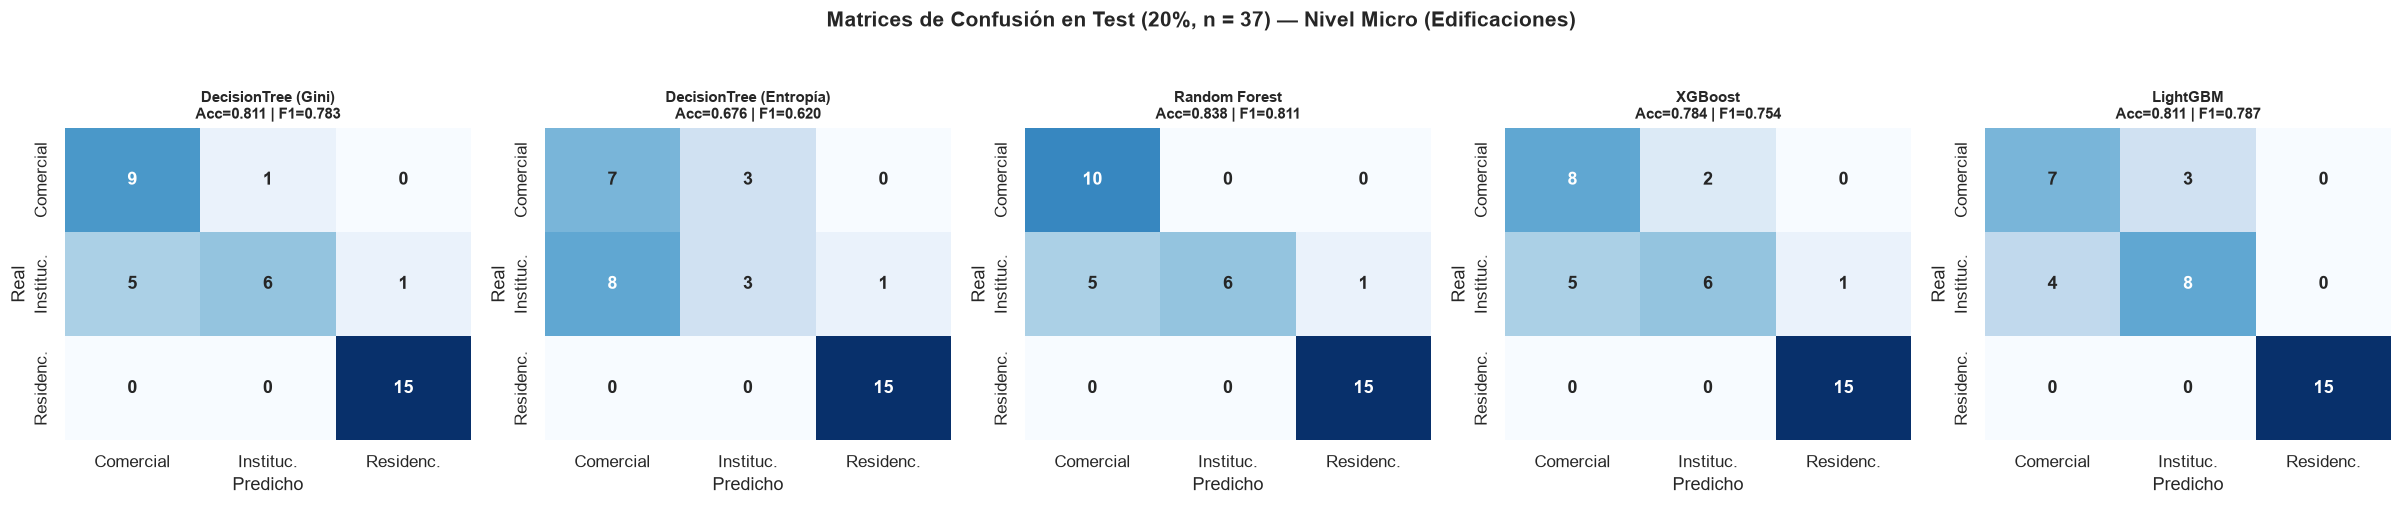

Figura guardada en: figures/02_matrices_confusion_micro.png


In [13]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
etiquetas_cortas = ['Comercial', 'Instituc.', 'Residenc.']

for ax, (nombre, y_pred) in zip(axes, predicciones_test.items()):
    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    f1m = f1_score(y_test, y_pred, average='macro')
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                annot_kws={'size': 12, 'weight': 'bold'},
                xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=ax)
    ax.set_title(f"{nombre}\nAcc={acc:.3f} | F1={f1m:.3f}", fontsize=10, fontweight='bold')
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

plt.suptitle("Matrices de Confusión en Test (20%, n = 37) — Nivel Micro (Edificaciones)",
             fontsize=13.5, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig(DIR_FIGURES / "02_matrices_confusion_micro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/02_matrices_confusion_micro.png")

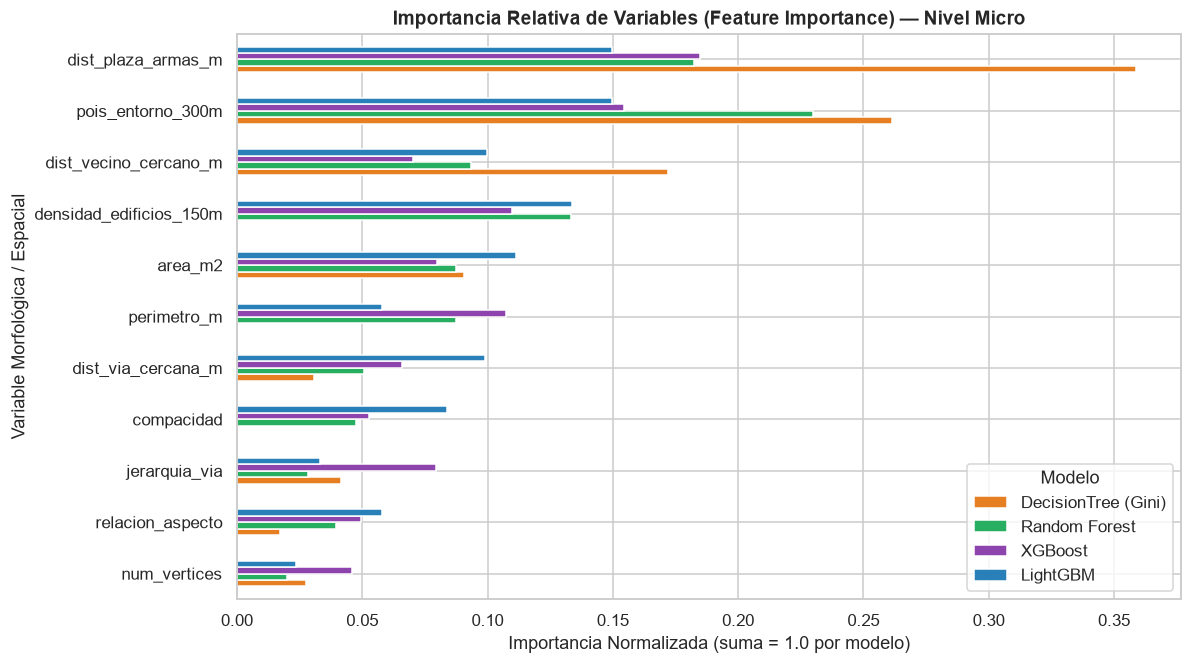

Figura guardada en: figures/02_feature_importance_micro.png


In [14]:
imp_df = pd.DataFrame(index=FEATURES)
for nombre in ['DecisionTree (Gini)', 'Random Forest', 'XGBoost', 'LightGBM']:
    imp = modelos_entrenados[nombre].feature_importances_
    imp_df[nombre] = imp / (imp.sum() + 1e-9)

imp_df['Promedio'] = imp_df.mean(axis=1)
imp_df = imp_df.sort_values('Promedio', ascending=True)

imp_df.drop(columns=['Promedio']).plot(
    kind='barh', figsize=(11, 6.2),
    color=['#e67e22', '#27ae60', '#8e44ad', '#2980b9'], edgecolor='white'
)
plt.title("Importancia Relativa de Variables (Feature Importance) — Nivel Micro", fontsize=12.5, fontweight='bold')
plt.xlabel("Importancia Normalizada (suma = 1.0 por modelo)")
plt.ylabel("Variable Morfológica / Espacial")
plt.legend(title="Modelo", loc="lower right")
plt.tight_layout()
plt.savefig(DIR_FIGURES / "02_feature_importance_micro.png", bbox_inches='tight')
plt.show()
print("Figura guardada en: figures/02_feature_importance_micro.png")

## 8. Aplicación Práctica: Reentrenamiento (100% Verificadas), Imputación y Mapa Interactivo Mejorado

Ahora pasamos a la **Fase de Imputación**:
1. Seleccionamos automáticamente el modelo ganador según **CV-5 F1-Score (Macro)**.
2. Lo **reentrenamos con el 100% de las `184` edificaciones verificadas**.
3. Predecimos la categoría urbana de las **`468` edificaciones sin etiqueta** en OpenStreetMap y exportamos `data_puno/puno_buildings_clasificados.geojson`.
4. Generamos un **Mapa Interactivo Folium mejorado** con pantalla completa, minimapa, distinción visual entre **Verificadas OSM** (borde negro sólido) vs. **Predichas ML** (borde punteado), popups detallados con sus variables espaciales y leyenda ejecutiva flotante.

In [15]:
nombre_ganador = df_resultados_micro.iloc[0]['Modelo']
cv_f1_ganador = df_resultados_micro.iloc[0]['CV-5 F1 (Macro)']
modelo_ganador = modelos[nombre_ganador]
print(f"Modelo ganador del Nivel Micro (por CV-5 F1 Macro): {nombre_ganador} ({cv_f1_ganador:.4f})")

# Reentrenar con el 100% de los 184 edificios verificados
modelo_ganador.fit(X, y)

# Predecir sobre las 468 edificaciones sin etiqueta
mask_unlabeled = b_utm['clase_uso'].isnull()
X_unlabeled = b_utm.loc[mask_unlabeled, FEATURES]
preds_unlabeled = le.inverse_transform(modelo_ganador.predict(X_unlabeled))

b_utm['origen_etiqueta'] = np.where(mask_unlabeled, 'Predicho (ML)', 'Verificado (OSM)')
b_utm['clase_final'] = b_utm['clase_uso'].copy()
b_utm.loc[mask_unlabeled, 'clase_final'] = preds_unlabeled

print("\nResumen final de las 652 edificaciones de Puno (Verificadas + Predichas):")
display(pd.crosstab(b_utm['clase_final'], b_utm['origen_etiqueta'], margins=True))

b_final_wgs84 = b_utm.to_crs("EPSG:4326")
b_final_wgs84.to_file(DIR_DATA_PUNO / "puno_buildings_clasificados.geojson", driver="GeoJSON")
print("Guardado exitosamente: data_puno/puno_buildings_clasificados.geojson")

Modelo ganador del Nivel Micro (por CV-5 F1 Macro): LightGBM (0.7496)

Resumen final de las 652 edificaciones de Puno (Verificadas + Predichas):


origen_etiqueta,Predicho (ML),Verificado (OSM),All
clase_final,,,
Comercial_Servicios,144,51,195
Institucional,227,60,287
Residencial,97,73,170
All,468,184,652


Guardado exitosamente: data_puno/puno_buildings_clasificados.geojson


In [16]:
# Mapa Interactivo Folium Mejorado — Nivel Micro (Edificaciones Clasificadas de Puno)
colores_mapa = {
    'Residencial': '#2e86de',          # Azul intenso
    'Comercial_Servicios': '#f39c12',  # Ámbar / Naranja
    'Institucional': '#8e44ad'         # Morado
}

m_micro = folium.Map(location=[-15.8402, -70.0280], zoom_start=15, tiles="OpenStreetMap")
Fullscreen(position='topright', title='Pantalla completa', title_cancel='Salir').add_to(m_micro)
MiniMap(toggle_display=True, minimized=True).add_to(m_micro)

# 1. Límite del Distrito de Puno
folium.GeoJson(
    gdf_boundary,
    name="Límite Distrito de Puno",
    style_function=lambda x: {'fillColor': 'none', 'color': '#2c3e50', 'weight': 2.2, 'dashArray': '6, 4'}
).add_to(m_micro)

# Preparar campos formateados para tooltip y popup
b_viz = b_final_wgs84[[
    'name', 'clase_final', 'origen_etiqueta', 'area_m2',
    'dist_plaza_armas_m', 'pois_entorno_300m', 'densidad_edificios_150m', 'geometry'
]].copy()
b_viz['name'] = b_viz['name'].fillna('Edificación sin nombre')
b_viz['area_m2'] = b_viz['area_m2'].round(1)
b_viz['dist_plaza_armas_m'] = b_viz['dist_plaza_armas_m'].round(0).astype(int)
b_viz['pois_entorno_300m'] = b_viz['pois_entorno_300m'].astype(int)
b_viz['densidad_edificios_150m'] = b_viz['densidad_edificios_150m'].astype(int)

# 2. Capas separadas por clase (distinguiendo visualmente Verificado vs. Predicho por borde y opacidad)
for clase, color in colores_mapa.items():
    sub = b_viz[b_viz['clase_final'] == clase]
    n_ver = int((sub['origen_etiqueta'] == 'Verificado (OSM)').sum())
    n_pre = int((sub['origen_etiqueta'] == 'Predicho (ML)').sum())

    fg = folium.FeatureGroup(name=f"{clase} ({len(sub)}: {n_ver} verif. + {n_pre} pred.)", show=True)
    folium.GeoJson(
        sub,
        style_function=lambda feat, c=color: {
            'fillColor': c,
            'color': '#111111' if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else c,
            'weight': 1.8 if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else 1.0,
            'dashArray': None if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else '3, 3',
            'fillOpacity': 0.88 if feat['properties']['origen_etiqueta'] == 'Verificado (OSM)' else 0.68
        },
        highlight_function=lambda feat: {'weight': 3.0, 'color': '#e74c3c', 'fillOpacity': 0.95},
        tooltip=folium.GeoJsonTooltip(
            fields=['name', 'clase_final', 'origen_etiqueta', 'area_m2'],
            aliases=['Edificio:', 'Clase:', 'Origen:', 'Área (m²):'],
            localize=True
        ),
        popup=folium.GeoJsonPopup(
            fields=['name', 'clase_final', 'origen_etiqueta', 'area_m2',
                    'dist_plaza_armas_m', 'pois_entorno_300m', 'densidad_edificios_150m'],
            aliases=['Edificio:', 'Categoría Final:', 'Origen:', 'Área (m²):',
                     'Dist. Plaza Armas (m):', 'POIs en 300m:', 'Edificios en 150m:'],
            localize=True, max_width=300
        )
    ).add_to(fg)
    fg.add_to(m_micro)

# 3. Marcador de referencia: Plaza de Armas de Puno
fg_ref = folium.FeatureGroup(name="Punto de Referencia (Plaza de Armas)", show=True)
folium.Marker(
    location=[-15.8402, -70.0280],
    tooltip="Plaza de Armas de Puno (centro de referencia espacial)",
    icon=folium.Icon(color='red', icon='star')
).add_to(fg_ref)
fg_ref.add_to(m_micro)

# 4. Leyenda ejecutiva flotante
leyenda_html = f'''
<div style="position: fixed; bottom: 25px; left: 25px; z-index: 9999; background: rgba(255,255,255,0.96);
            padding: 12px 15px; border: 1.5px solid #2c3e50; border-radius: 8px; font-size: 12px;
            box-shadow: 0 3px 10px rgba(0,0,0,0.22); line-height: 1.5; max-width: 270px;">
  <div style="font-weight: bold; font-size: 13px; color: #1c2833; border-bottom: 1px solid #d5d8dc; padding-bottom: 4px; margin-bottom: 6px;">
    Nivel Micro — Edificaciones de Puno
  </div>
  <b>Categorías (652 edificios):</b><br>
  <span style="color:#2e86de; font-size:14px;">■</span> Residencial (170)<br>
  <span style="color:#8e44ad; font-size:14px;">■</span> Institucional (287)<br>
  <span style="color:#f39c12; font-size:14px;">■</span> Comercial / Servicios (195)<br>
  <hr style="margin: 6px 0; border: none; border-top: 1px solid #eaecee;">
  <b>Origen de etiqueta:</b><br>
  <span style="display:inline-block; width:12px; height:10px; border:2px solid #111; background:#bbb; vertical-align:middle;"></span> Verificado OSM (184)<br>
  <span style="display:inline-block; width:12px; height:10px; border:1.5px dashed #555; background:#ddd; vertical-align:middle;"></span> Predicho ML — {nombre_ganador} (468)<br>
  <span style="color:#566573; font-size:11px;">CV-5 F1 Macro: <b>{cv_f1_ganador:.4f}</b> | Clic en un edificio para ver detalles</span>
</div>
'''
m_micro.get_root().html.add_child(folium.Element(leyenda_html))
folium.LayerControl(collapsed=False).add_to(m_micro)

ruta_html_micro = DIR_DATA_PUNO / "mapa_micro_edificaciones.html"
m_micro.save(ruta_html_micro)
print(f"Mapa interactivo mejorado guardado en: {ruta_html_micro.resolve()}")
m_micro

Mapa interactivo mejorado guardado en: C:\Users\ronim\OneDrive\Documents\Zonas_Puno\data_puno\mapa_micro_edificaciones.html
